# 02 · Baselines, modelo global y backtest (h = 3)

Fases 2–3 de DECISIONES.md. Features documentados en `reports/FEATURES.md`; diseño del backtest en LOG_DECISIONES #19.

- **Validación** (objetivos jul-2024 → jun-2025, orígenes abr-2024 → mar-2025): hiperparámetros, ablaciones de
  features, ruta por segmento y k del jerárquico. El último objetivo es el primer origen de prueba (jun-2025), así
  que ninguna decisión usa datos posteriores.
- **Prueba** (objetivos sep-2025 → sep-2026): solo se evalúa lo elegido en validación. ⚠️ Cae en el nivel bajo
  posterior a caida_2024 (§13: el test es un periodo anómalo). Jul–ago 2025 (periodo puente) solo se pronostican
  para la simulación de inventario.
- **Métrica de decisión: WAPE + sesgo** (`metricas.adopta`): un candidato reemplaza a la referencia solo si baja el
  WAPE en ≥ 0.5 pp, gana en WAPE en ≥ 2/3 de los orígenes y no empeora el |sesgo| en más de 1 pp. MASE, RMSSE,
  relMAE y MAPE (solo y > 0) se reportan como secundarias. Las métricas `_total` suman los SKUs por mes (vista de
  compras).
- SKUs dormidos (≥ 12 meses sin venta; repuestos que pueden volver) no se evalúan: se reporta su reactivación.
- Proyecto/base: se usa la clase Syntetos–Boylan como proxy (grumosa/intermitente = proyecto, suave/errática = base).

**Modelo elegido para los SKUs maduros: `TD_estado`** (§3.8, LOG #45): según el estado de la familia en el origen,
`TD_mix_k3` si viene cayendo, `TD_mix_k12` si viene subiendo y `ML_base` si está estable. Jóvenes: `Media_post` (§5).
Las cifras de las celdas de lectura y de los hallazgos son de esta corrida (h = 3, regla de limpieza por clase,
WAPE + sesgo).

In [ ]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO, FMT_MILES
from features import H
from metricas import adopta, elegir, por_origen, resumen

aplicar()
pd.set_option("display.width", 200, "display.max_columns", 40)
RES = RAIZ / "data" / "processed" / "resultados"
FIG = RAIZ / "reports" / "figuras"
val = pd.read_parquet(RES / "pronosticos_validacion.parquet")
test = pd.read_parquet(RES / "pronosticos_prueba.parquet")
meta = json.loads((RES / "meta.json").read_text(encoding="utf-8"))
cob = pd.read_csv(RES / "cobertura.csv", parse_dates=["mes_obj"])
clas = pd.read_parquet(RAIZ / "data" / "processed" / "clasificacion_sku.parquet")[["id_articulo", "abc", "xyz"]]
TIPO = {"grumosa": "proyecto (proxy)", "intermitente": "proyecto (proxy)", "suave": "base", "errática": "base"}
for d in (val, test):
    d["tipo"] = d.clase.map(TIPO)

CLASICOS = ["Naive", "SNaive", "MA12", "ETS", "SARIMA_fam", "Croston", "SBA", "TSB", "Ruta_clasica"]
ML = [c for c in val.columns if c.startswith("ML_")]
FMT = {"MASE": "{:.3f}", "RMSSE": "{:.3f}", "WAPE": "{:.1%}", "relMAE": "{:.3f}", "sesgo": "{:+.1%}",
       "MAPE_y>0": "{:.0%}", "WAPE_total": "{:.1%}", "sesgo_total": "{:+.1%}"}
def tabla(df, modelos):
    return resumen(df, modelos).sort_values("WAPE").style.format(FMT)

## 1. Set evaluado y cobertura

In [ ]:
for n, d in [("validación", val), ("prueba", test)]:
    print(f"{n}: {len(d):,} pares SKU-origen · {d.id_articulo.nunique():,} SKUs · {d.origen.nunique()} orígenes · "
          f"{d.y.sum():,.0f} u. reales")
cob["pct_fuera"] = cob.u_fuera_set / cob.u_total
cob["pct_jovenes"], cob["pct_dormidos"] = cob.u_jovenes / cob.u_total, cob.u_dormidos / cob.u_total
print(f"Unidades del mes objetivo fuera del set: mediana {cob.pct_fuera.median():.1%}, "
      f"rango {cob.pct_fuera.min():.1%}–{cob.pct_fuera.max():.1%}")
print(f"  jóvenes (< 13 meses o nacidos después del origen): mediana {cob.pct_jovenes.median():.1%}")
print(f"  dormidos que se reactivan (sin venta en los 12 meses previos al origen): mediana {cob.pct_dormidos.median():.2%}, "
      f"máx. {cob.pct_dormidos.max():.2%}")
print("SKUs dormidos por origen y cuántos venden en el mes objetivo (reactivación):")
print(cob.set_index("mes_obj")[["skus_dormidos", "skus_dormidos_reactivados", "u_dormidos"]].T.to_string())
print("Clases SB en prueba:", test.clase.value_counts().to_dict(), "· tipo:", test.tipo.value_counts().to_dict())

validación: 9,416 pares SKU-origen · 881 SKUs · 12 orígenes · 1,277,781 u. reales
prueba: 10,301 pares SKU-origen · 913 SKUs · 13 orígenes · 1,423,319 u. reales
Unidades del mes objetivo fuera del set: mediana 2.0%, rango 1.3%–3.1%
  jóvenes (< 13 meses o nacidos después del origen): mediana 2.0%
  dormidos que se reactivan (sin venta en los 12 meses previos al origen): mediana 0.01%, máx. 0.04%
SKUs dormidos por origen y cuántos venden en el mes objetivo (reactivación):
mes_obj                    2024-07-01  2024-08-01  2024-09-01  2024-10-01  2024-11-01  2024-12-01  2025-01-01  2025-02-01  2025-03-01  2025-04-01  2025-05-01  2025-06-01  2025-09-01  2025-10-01  2025-11-01  2025-12-01  2026-01-01  2026-02-01  2026-03-01  2026-04-01  2026-05-01  2026-06-01  2026-07-01  2026-08-01  2026-09-01  2025-07-01  2025-08-01
skus_dormidos                  1310.0      1322.0      1330.0      1339.0      1345.0      1356.0      1361.0      1373.0      1393.0      1407.0      1419.0      1432.0     

## 2. Validación: hiperparámetros del modelo global

In [ ]:
print(pd.DataFrame(meta["hiper"]).T[["WAPE", "sesgo", "MASE", "RMSSE"]].round(3).to_string())
print("Elegido (regla WAPE + sesgo frente a A):", meta["hiper_elegido"])
print("Meses bajos del total detectados (excluidos como objetivo de entrenamiento):", meta.get("meses_bajos"))

    WAPE  sesgo   MASE  RMSSE
A  0.469  0.193  0.788  0.666
B  0.493  0.220  0.817  0.678
C  0.476  0.203  0.785  0.664
Elegido (regla WAPE + sesgo frente a A): A
Meses bajos del total detectados (excluidos como objetivo de entrenamiento): {'caida_2020_04_05': ['2020-04', '2020-05']}


## 3. Validación: todos los modelos

In [ ]:
tabla(val, CLASICOS + ML)

,MASE,RMSSE,WAPE,relMAE,sesgo,MAPE_y>0,WAPE_total,sesgo_total
Ruta_clasica,0.825,0.687,45.9%,0.662,+15.2%,210%,16.8%,+15.2%
SBA,0.900,0.724,46.0%,0.664,+15.2%,207%,16.9%,+15.2%
ML_base,0.788,0.666,46.9%,0.677,+19.3%,199%,22.3%,+19.3%
ML_sin_limpieza,0.801,0.672,47.8%,0.690,+20.5%,201%,23.4%,+20.5%
TSB,0.809,0.679,48.1%,0.694,+20.6%,214%,21.2%,+20.6%
ML_devol,0.805,0.672,48.1%,0.695,+21.5%,205%,23.9%,+21.5%
MA12,0.831,0.677,48.2%,0.696,+20.1%,207%,21.7%,+20.1%
Croston,0.930,0.738,48.8%,0.704,+21.3%,219%,21.8%,+21.3%
SARIMA_fam,0.825,0.680,49.8%,0.719,+22.7%,209%,23.1%,+22.7%
Naive,0.872,0.800,53.7%,0.775,+5.7%,200%,18.5%,+5.7%


### 3.1 Ablaciones de features (validación y prueba)

Diferencia frente a `ML_base` (negativo = mejora). **Regla de adopción** (WAPE + sesgo, `metricas.adopta`): una
variante reemplaza a `ML_base` solo si en **validación** baja el WAPE en ≥ 0.5 pp, gana en WAPE en ≥ 2/3 de los
orígenes y no empeora el |sesgo| en más de 1 pp; si no, gana el modelo más simple. La prueba solo confirma.
`ML_sin_limpieza` usa la serie cruda en lags y medias (la limpieza solo aplica a suaves/erráticos).

In [ ]:
def ablacion(d):
    r = resumen(d, ML)
    return (r - r.loc["ML_base"])[["WAPE", "sesgo", "WAPE_total", "MASE", "RMSSE"]]
ab = pd.concat({"validación": ablacion(val), "prueba": ablacion(test)}, axis=1)
print(ab.round(4).to_string())

otros = [m for m in ML if m != "ML_base"] + ["Ruta_clasica"]
for n, d in [("validación", val), ("prueba", test)]:
    po = por_origen(d, ["ML_base"] + otros)
    gana = (po[otros].lt(po.ML_base, axis=0)).sum()
    print(f"\n{n}: orígenes (de {len(po)}) donde cada modelo mejora el WAPE de ML_base:", gana.to_dict())

cumplen = [m for m in ML if m != "ML_base" and adopta(val, m, "ML_base")]
mejor_ml = elegir(val, ML, "ML_base")
print("\nVariantes que cumplen la regla:", cumplen or "ninguna", "→ modelo final:", mejor_ml)

                validación                                     prueba                                   
                      WAPE   sesgo WAPE_total    MASE   RMSSE    WAPE   sesgo WAPE_total    MASE   RMSSE
ML_base             0.0000  0.0000     0.0000  0.0000  0.0000  0.0000  0.0000     0.0000  0.0000  0.0000
ML_sin_limpieza     0.0085  0.0115     0.0116  0.0130  0.0054 -0.0011 -0.0061     0.0025 -0.0074 -0.0034
ML_devol            0.0119  0.0214     0.0165  0.0169  0.0053 -0.0009  0.0025    -0.0051 -0.0002 -0.0010

validación: orígenes (de 12) donde cada modelo mejora el WAPE de ML_base: {'ML_sin_limpieza': 4, 'ML_devol': 5, 'Ruta_clasica': 6}

prueba: orígenes (de 13) donde cada modelo mejora el WAPE de ML_base: {'ML_sin_limpieza': 5, 'ML_devol': 7, 'Ruta_clasica': 6}

Variantes que cumplen la regla: ninguna → modelo final: ML_base


### 3.2 Ruta por segmento (clase Syntetos–Boylan en el origen)

In [ ]:
print("Ruta elegida en validación (regla WAPE + sesgo frente a SNaive, dentro de cada clase):", meta["ruta"])
for met in ("WAPE", "sesgo"):
    seg = pd.concat({c: resumen(g, CLASICOS[:-1] + [mejor_ml])[met] for c, g in val.groupby("clase")}, axis=1)
    print(f"\n{met} por clase (validación):"); print(seg.round(3).to_string())

Ruta elegida en validación (regla WAPE + sesgo frente a SNaive, dentro de cada clase): {'errática': 'SBA', 'grumosa': 'SARIMA_fam', 'intermitente': 'TSB', 'suave': 'SBA'}



WAPE por clase (validación):
            errática  grumosa  intermitente  suave
Naive          0.704    1.165         2.267  0.436
SNaive         0.964    1.488         3.034  0.533
MA12           0.662    1.134         2.527  0.375
ETS            0.805    1.173         2.611  0.399
SARIMA_fam     0.690    1.113         2.420  0.384
Croston        0.667    1.271         3.260  0.379
SBA            0.636    1.240         3.133  0.352
TSB            0.656    1.130         2.399  0.375
ML_base        0.620    1.060         2.425  0.378



sesgo por clase (validación):
            errática  grumosa  intermitente  suave
Naive          0.070   -0.022         0.853  0.050
SNaive         0.433    0.132         1.483  0.268
MA12           0.260    0.082         1.180  0.170
ETS            0.349    0.137         1.196  0.179
SARIMA_fam     0.286    0.076         1.061  0.196
Croston        0.276    0.207         1.933  0.179
SBA            0.212    0.147         1.787  0.120
TSB            0.264    0.075         1.005  0.175
ML_base        0.231    0.060         1.115  0.174


### 3.3 Jerárquico middle-out: familia (nivel × índice) repartida con el ML (`src/jerarquico.py`, LOG #32)

En cada origen, el total de la familia = **nivel** (media desestacionalizada de los últimos k meses) × **índice
estacional** de la familia, con datos ≤ origen. Se reparte entre los SKUs con la cuota histórica (`TD_hist`), con la
cuota del `ML_base` (`TD_ML`) o con volumen = promedio entre nivel × índice y Σ `ML_base` (`TD_mix`). k ∈ {3, 6, 12}
se elige en validación con la regla WAPE + sesgo frente a k = 12. `SARIMA_fam` (otro top-down, con cuota histórica)
va de referencia. Misma regla de adopción frente a `ML_base`. Ninguna variante con un solo k pasa la regla en los dos
periodos; la combinación por estado de la familia (`TD_estado`, que usa k = 3 en caídas y k = 12 en subidas) sí, y
se desarrolla en §3.6–3.8.

In [ ]:
jer = {n: d.merge(pd.read_parquet(RES / f"pronosticos_{p}_jer.parquet"), on=["id_articulo", "origen", "mes_obj"])
       for n, d, p in [("validación", val, "validacion"), ("prueba", test, "prueba")]}
meta_jer = json.loads((RES / "meta_jer.json").read_text(encoding="utf-8"))
k = meta_jer["k_elegido"]
print("WAPE de TD_ML por ventana k (validación):", {c: round(v, 3) for c, v in meta_jer["WAPE_por_k"].items()}, "→", k)
JER = ["ML_base", "SARIMA_fam", f"TD_hist_{k}", f"TD_ML_{k}", f"TD_mix_{k}"]
for n, d in jer.items():
    r = resumen(d, JER)
    po = por_origen(d, JER)
    r["gana_a_ML"] = [f"{(po[m] < po.ML_base).sum()}/{len(po)}" if m != "ML_base" else "" for m in JER]
    print(f"\n{n}"); print(r[["WAPE", "sesgo", "WAPE_total", "MASE", "RMSSE", "gana_a_ML"]].round(3).to_string())
print("\n¿Cumplen la regla frente a ML_base en validación?:", {m: adopta(jer["validación"], m, "ML_base") for m in JER[1:]})

# ¿el total de la familia (nivel × índice) es mejor que la suma del ML?
for n, d in jer.items():
    g = d.groupby(["familia", "mes_obj"]).agg(y=("y", "sum"), ML=("ML_base", "sum"), F=(f"F_fam_{k}", "first"),
                                              mix=(f"TD_mix_{k}", "sum"))
    w = {c: (g[c] - g.y).abs().sum() / g.y.sum() for c in ["ML", "F", "mix"]}
    print(f"{n}: WAPE familia-mes → Σ ML {w['ML']:.3f} · nivel × índice {w['F']:.3f} · mix {w['mix']:.3f}")

WAPE de TD_ML por ventana k (validación): {'TD_ML_k3': 0.455, 'TD_ML_k6': 0.468, 'TD_ML_k12': 0.483} → k12

validación
              WAPE  sesgo  WAPE_total   MASE  RMSSE gana_a_ML
ML_base      0.469  0.193       0.223  0.788  0.666          
SARIMA_fam   0.498  0.227       0.231  0.825  0.680      3/12
TD_hist_k12  0.486  0.199       0.234  0.839  0.686      6/12
TD_ML_k12    0.483  0.199       0.234  0.803  0.678      6/12
TD_mix_k12   0.470  0.196       0.228  0.792  0.668      7/12

prueba
              WAPE  sesgo  WAPE_total   MASE  RMSSE gana_a_ML
ML_base      0.490  0.035       0.099  0.952  0.744          
SARIMA_fam   0.531  0.113       0.132  0.957  0.758      0/13
TD_hist_k12  0.496  0.052       0.107  0.970  0.754      4/13
TD_ML_k12    0.493  0.052       0.107  0.958  0.747      4/13
TD_mix_k12   0.488  0.043       0.088  0.952  0.742      7/13



¿Cumplen la regla frente a ML_base en validación?: {'SARIMA_fam': False, 'TD_hist_k12': False, 'TD_ML_k12': False, 'TD_mix_k12': False}
validación: WAPE familia-mes → Σ ML 0.283 · nivel × índice 0.307 · mix 0.289
prueba: WAPE familia-mes → Σ ML 0.231 · nivel × índice 0.240 · mix 0.228


### 3.4 ¿La regla nueva de limpieza perjudica los pronósticos? (`src/regimen.py`, LOG #42)

La corrida anterior no es comparable directamente (h = 4, `order_date`, otra ventana de validación). Se hace una
**ablación con el código actual**: mismo `ML_base`, mismos hiperparámetros y orígenes, revirtiendo cada parte de la
regla (LOG #39):
- `objetivo_crudo`: entrena con la venta cruda en lugar de `y_entreno`.
- `limpieza_todos`: limpia todas las clases SB, no solo suaves y erráticas.
- `sin_piso_covid_fijo`: sin el piso de meses bajos; excluye mar–jun 2020 fijo, como antes.
- `adi_viejo`: ADI con los meses hasta el origen (incluye los ceros posteriores a la última venta).
- `regla_vieja`: todo lo anterior junto.

La **evaluación siempre es contra la venta cruda** (se verifica abajo): la limpieza solo cambia lo que el modelo usa
para entrenar.

In [ ]:
import features as ft
import jerarquico as jq
import regimen as rg

datos = ft.Datos.cargar()
k_ = datos.skus.get_indexer(val.id_articulo)
print("Meses bajos detectados:", {n: [f"{m:%Y-%m}" for m in v] for n, v in ft.nombres_bajos(datos.bajo).items()})
print("¿La y de validación es la venta cruda del panel?:",
      np.allclose(val.y.to_numpy(), datos.y[k_, ft.MESES.get_indexer(val.mes_obj)]))

ABL = ["actual", "objetivo_crudo", "limpieza_todos", "sin_piso_covid_fijo", "adi_viejo", "regla_vieja"]
abl = {n: pd.read_parquet(RES / f"regimen_ablacion_{p}.parquet") for n, p in [("validación", "validacion"), ("prueba", "prueba")]}
for n, d in abl.items():
    r = resumen(d.assign(escala_mae=1, escala_mse=1, SNaive=d.actual), ABL)[["WAPE", "sesgo"]]
    po = por_origen(d, ABL)
    r["variante gana a actual"] = [f"{(po[m] < po.actual).sum()}/{len(po)}" if m != "actual" else "" for m in ABL]
    r["actual cumple la regla frente a ella"] = [adopta(d, "actual", m) if m != "actual" else "" for m in ABL]
    print(f"\n{n}"); print(r.round(3).to_string())

Meses bajos detectados: {'caida_2020_04_05': ['2020-04', '2020-05']}
¿La y de validación es la venta cruda del panel?: True

validación
                      WAPE  sesgo variante gana a actual actual cumple la regla frente a ella
actual               0.469  0.193                                                            
objetivo_crudo       0.491  0.225                   1/12                                 True
limpieza_todos       0.466  0.176                   7/12                                False
sin_piso_covid_fijo  0.467  0.188                   8/12                                False
adi_viejo            0.475  0.203                   6/12                                False
regla_vieja          0.495  0.216                   2/12                                 True



prueba
                      WAPE  sesgo variante gana a actual actual cumple la regla frente a ella
actual               0.490  0.035                                                            
objetivo_crudo       0.497  0.053                   4/13                                 True
limpieza_todos       0.489  0.025                   8/13                                False
sin_piso_covid_fijo  0.490  0.029                   6/13                                False
adi_viejo            0.491  0.035                   7/13                                False
regla_vieja          0.495  0.045                   3/13                                 True


In [ ]:
# el sesgo de validación es del periodo: los modelos con serie cruda (sin limpieza) tienen el mismo patrón por mes
for n, d, base in [("validación", abl["validación"], val), ("prueba", abl["prueba"], test)]:
    x = d.merge(base[["id_articulo", "origen", "MA12", "Ruta_clasica", "SNaive"]], on=["id_articulo", "origen"])
    g = x.groupby("mes_obj")[["y", "actual", "regla_vieja", "MA12", "Ruta_clasica", "SNaive"]].sum()
    s = (g.drop(columns="y").div(g.y, axis=0) - 1) * 100
    s.index = s.index.strftime("%b-%y")
    print(f"\nSesgo por mes objetivo, {n} (%):"); print(s.round(0).T.to_string())


Sesgo por mes objetivo, validación (%):
mes_obj       Jul-24  Aug-24  Sep-24  Oct-24  Nov-24  Dec-24  Jan-25  Feb-25  Mar-25  Apr-25  May-25  Jun-25
actual          41.0    14.0    24.0    11.0    48.0    44.0    18.0    25.0    -6.0    31.0   -10.0     8.0
regla_vieja     45.0    16.0    22.0    17.0    54.0    52.0    27.0    26.0   -16.0    40.0   -10.0     7.0
MA12            37.0    13.0    20.0    16.0    40.0    43.0    19.0    31.0    -1.0    42.0    -8.0     9.0
Ruta_clasica    27.0     5.0    10.0     6.0    31.0    35.0    17.0    31.0    -2.0    42.0    -7.0     9.0
SNaive          32.0    36.0    25.0    70.0    59.0    32.0    22.0    48.0    -3.0    73.0     8.0     3.0

Sesgo por mes objetivo, prueba (%):
mes_obj       Sep-25  Oct-25  Nov-25  Dec-25  Jan-26  Feb-26  Mar-26  Apr-26  May-26  Jun-26  Jul-26  Aug-26  Sep-26
actual          -5.0    -4.0    11.0    13.0    14.0    22.0   -13.0     9.0    16.0     1.0    10.0   -10.0    -5.0
regla_vieja    -11.0    -0.0    13

**Lectura.**
- **La regla nueva no perjudica: mejora.** Frente a la regla vieja completa, `ML_base` baja el WAPE 2.6 pp en validación
  (0.469 vs 0.495) y 0.5 pp en prueba (0.490 vs 0.495), con menos sesgo, y cumple la regla de adopción en ambos.
- **La mejora viene de entrenar con el objetivo limpio:** volver al objetivo crudo cuesta 2.2 pp de WAPE y 3 pp de
  sesgo en validación. El piso de meses bajos y el ADI hasta la última venta son casi neutrales.
- **Matiz:** limpiar también grumosos e intermitentes sale apenas mejor (−0.3 pp de WAPE, −1.7 pp de sesgo, 7–8 de
  12–13 orígenes), sin pasar la regla. Probablemente porque baja el pronóstico en un periodo en que todos
  sobre-pronostican; se mantiene sin limpiar esas clases porque sus picos son demanda de proyecto.
- **El +19 % de sesgo de validación es del periodo, no de la regla.** MA12, la ruta clásica y SNaive (venta cruda, sin
  limpieza) tienen el mismo patrón por mes: +27 a +59 % en jul y nov–dic 2024 y +31 a +73 % en abr-2025. La ventana
  de validación cae en caida_2024 y todo modelo entrenado con el nivel previo sobre-pronostica.

### 3.5 ETS como estadístico de la familia (LOG #43)

Mismo esquema middle-out de 3.3, pero el volumen de la familia lo pronostica un **AutoETS estacional** (s = 12) en lugar
del nivel × índice. `TD_ML_ets` = ETS decide el volumen de la familia y el ML lo reparte entre sus SKUs.

In [ ]:
ETSM = ["ML_base", f"TD_ML_{k}", "TD_ML_k3", "TD_ML_ets", "TD_mix_k3", "TD_mix_ets", "TD_hist_ets"]
ETSM = list(dict.fromkeys(ETSM))
for n, p in [("validación", "validacion"), ("prueba", "prueba")]:
    d = jer[n].merge(pd.read_parquet(RES / f"regimen_ets_{p}.parquet"), on=["id_articulo", "origen"])
    r = resumen(d, ETSM)[["WAPE", "sesgo", "MASE"]]
    po = por_origen(d, ETSM)
    r["gana_a_ML"] = [f"{(po[m] < po.ML_base).sum()}/{len(po)}" if m != "ML_base" else "" for m in ETSM]
    r["cumple regla"] = [adopta(d, m, "ML_base") if m != "ML_base" else "" for m in ETSM]
    print(f"\n{n} (nivel SKU)"); print(r.round(3).to_string())
    g = d.groupby(["familia", "origen"]).agg(y=("y", "sum"), ML=("ML_base", "sum"), k3=("F_fam_k3", "first"),
                                             k12=("F_fam_k12", "first"), ets=("F_fam_ets", "first"))
    g["mix_k3"] = (g.k3 + g.ML) / 2
    print("nivel familia:", {c: f"WAPE {(g[c] - g.y).abs().sum() / g.y.sum():.3f} / sesgo {(g[c] - g.y).sum() / g.y.sum():+.1%}"
                             for c in ["ML", "k3", "k12", "ets", "mix_k3"]})


validación (nivel SKU)
              WAPE  sesgo   MASE gana_a_ML cumple regla
ML_base      0.469  0.193  0.788                       
TD_ML_k12    0.483  0.199  0.803      6/12        False
TD_ML_k3     0.455  0.095  0.767      8/12         True
TD_ML_ets    0.479  0.210  0.791      6/12        False
TD_mix_k3    0.449  0.144  0.771      8/12         True
TD_mix_ets   0.470  0.202  0.787      6/12        False
TD_hist_ets  0.482  0.210  0.827      5/12        False
nivel familia: {'ML': 'WAPE 0.283 / sesgo +19.3%', 'k3': 'WAPE 0.283 / sesgo +9.5%', 'k12': 'WAPE 0.307 / sesgo +19.9%', 'ets': 'WAPE 0.303 / sesgo +21.0%', 'mix_k3': 'WAPE 0.269 / sesgo +14.4%'}

prueba (nivel SKU)
              WAPE  sesgo   MASE gana_a_ML cumple regla
ML_base      0.490  0.035  0.952                       
TD_ML_k12    0.493  0.052  0.958      4/13        False
TD_ML_k3     0.517  0.052  0.945      5/13        False
TD_ML_ets    0.511  0.072  0.953      4/13        False
TD_mix_k3    0.496  0.043  0.944

nivel familia: {'ML': 'WAPE 0.231 / sesgo +3.5%', 'k3': 'WAPE 0.267 / sesgo +5.2%', 'k12': 'WAPE 0.240 / sesgo +5.2%', 'ets': 'WAPE 0.271 / sesgo +7.2%', 'mix_k3': 'WAPE 0.238 / sesgo +4.3%'}


**Lectura.** ETS **no mejora** el volumen de la familia. A nivel familia queda igual o peor que el nivel de 3 meses
(validación 0.303 vs 0.283; prueba 0.271 vs 0.267) y su sesgo es el más alto (+21 % y +7 %): no se adapta tan rápido a
caida_2024. En prueba el ML predice mejor el total de la familia (0.231) que cualquier estadístico. Ninguna variante con
ETS cumple la regla frente a `ML_base`. El esquema middle-out no es el problema: el ML ya pronostica bien el volumen de
la familia; lo que aporta la estadística de familia es reaccionar rápido a un cambio de nivel (3.6).

### 3.6 ¿Quién se adapta mejor después de una caída o una subida? (LOG #44)

Línea de tiempo continua: validación + puente + prueba (objetivos jul-2024 → sep-2026). En cada origen, el **estado de
la familia** se calcula solo con lo que se sabe en ese momento: r = media de los últimos 3 meses / media de los 12
anteriores (venta cruda de toda la familia). **Caída** si r < 0.85, **subida** si r > 1.15, **estable** en medio;
`tramo` = meses seguidos en ese estado. El error se mide contra la venta cruda, sumando los SKUs del set por familia.

In [ ]:
MODR = ["ML_base", "TD_mix_k3", "TD_mix_k12", "TD_ML_k3"]
est, racha, r_est = rg.estado_familia(datos)
lt = rg.etiquetar(rg.linea_tiempo(), est, racha)
fam_lt = lt.groupby(["familia", "origen", "mes_obj", "estado", "tramo"], observed=True)[["y"] + MODR].sum().reset_index()

def por_grupo(x, por):
    g = x.groupby(por, observed=True)
    out = {}
    for m in MODR:
        out[(m, "WAPE")] = g.apply(lambda s: (s[m] - s.y).abs().sum() / s.y.sum(), include_groups=False)
        out[(m, "sesgo")] = g.apply(lambda s: (s[m] - s.y).sum() / s.y.sum(), include_groups=False)
    out[("", "% unidades")] = g.y.sum() / x.y.sum()
    return pd.DataFrame(out)

print("Nivel familia, por estado en el origen y meses en ese estado:")
print(por_grupo(fam_lt, ["estado", "tramo"]).round(3).to_string())
fam_lt["gana_k3"] = (fam_lt.TD_mix_k3 - fam_lt.y).abs() < (fam_lt.ML_base - fam_lt.y).abs()
print("\n% de celdas familia-origen donde TD_mix_k3 tiene menor error que ML_base:")
print((fam_lt.groupby(["estado", "tramo"], observed=True).gana_k3.mean() * 100).round(0).unstack().to_string())

Nivel familia, por estado en el origen y meses en ese estado:
              ML_base        TD_mix_k3        TD_mix_k12        TD_ML_k3                  
                 WAPE  sesgo      WAPE  sesgo       WAPE  sesgo     WAPE  sesgo % unidades
estado  tramo                                                                             
caída   1–2 m   0.235  0.069     0.228  0.009      0.258  0.097    0.243 -0.051      0.182
        3–5 m   0.305  0.097     0.299  0.010      0.315  0.117    0.313 -0.078      0.106
        6+ m    0.403  0.249     0.379  0.105      0.433  0.259    0.386 -0.039      0.039
estable 1–2 m   0.230  0.034     0.222  0.025      0.220  0.030    0.234  0.016      0.239
        3–5 m   0.246  0.044     0.248  0.066      0.244  0.048    0.264  0.088      0.164
        6+ m    0.218  0.168     0.208  0.158      0.226  0.177    0.221  0.149      0.129
subida  1–2 m   0.237 -0.021     0.240  0.076      0.206 -0.016    0.304  0.174      0.084
        3–5 m   0.451  0.099

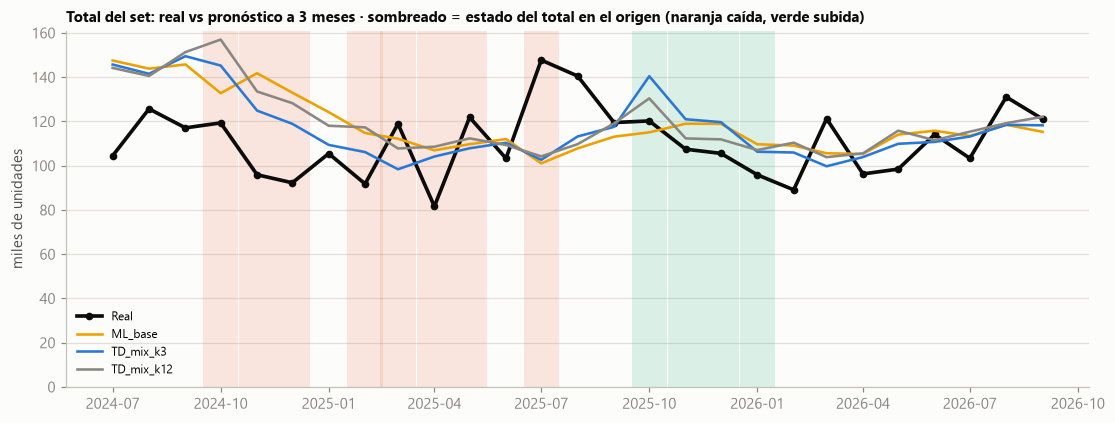

Sesgo del total por mes objetivo (%):
        estado (origen)  ML_base  TD_mix_k3  TD_mix_k12  TD_ML_k3
mes_obj                                                          
Jul-24          estable     41.0       39.0        38.0      38.0
Aug-24          estable     14.0       13.0        12.0      11.0
Sep-24          estable     24.0       28.0        29.0      31.0
Oct-24            caída     11.0       22.0        32.0      32.0
Nov-24            caída     48.0       30.0        39.0      13.0
Dec-24            caída     44.0       29.0        39.0      14.0
Jan-25          estable     18.0        4.0        12.0     -10.0
Feb-25            caída     25.0       16.0        28.0       6.0
Mar-25            caída     -6.0      -17.0        -9.0     -29.0
Apr-25            caída     31.0       28.0        33.0      24.0
May-25            caída    -10.0      -11.0        -8.0     -13.0
Jun-25          estable      8.0        7.0         6.0       5.0
Jul-25            caída    -32.0      

In [ ]:
tot_lt = lt.groupby("mes_obj")[["y"] + MODR].sum() / 1e3
e_tot = est.TOTAL.reindex(tot_lt.index - pd.DateOffset(months=H)).to_numpy()   # estado del total en el origen
fig, ax = plt.subplots(figsize=(12, 4.2))
for i, (m, e) in enumerate(zip(tot_lt.index, e_tot)):
    if e != "estable":
        ax.axvspan(m - pd.DateOffset(days=15), m + pd.DateOffset(days=15), color=COLORES[1] if e == "caída" else COLORES[2],
                   alpha=.15, lw=0)
ax.plot(tot_lt.index, tot_lt.y, color="#0b0b0b", lw=2.4, marker="o", ms=4, label="Real")
for m, c in zip(MODR[:3], [COLORES[3], AZUL, GRIS]):
    ax.plot(tot_lt.index, tot_lt[m], lw=1.7, color=c, label=m)
ax.set_ylim(0, None); ax.set_ylabel("miles de unidades"); ax.legend(fontsize=8, loc="lower left")
ax.set_title(f"Total del set: real vs pronóstico a {H} meses · sombreado = estado del total en el origen "
             "(naranja caída, verde subida)", fontsize=10)
fig.savefig(FIG / "28_adaptacion_total.png"); plt.show()
s = (tot_lt[MODR].div(tot_lt.y, axis=0) - 1) * 100
s.insert(0, "estado (origen)", e_tot)
s.index = s.index.strftime("%b-%y")
print("Sesgo del total por mes objetivo (%):"); print(s.round(0).to_string())

In [ ]:
# regla causal por estado: A = TD_mix_k3 en caída; B = además TD_mix_k12 en subida
lt["Estado_A"] = rg.regla_estado(lt, {"caída": "TD_mix_k3"})
lt["Estado_B"] = rg.regla_estado(lt)
CANDR = ["ML_base", "TD_mix_k3", "TD_mix_k12", "Estado_A", "Estado_B"]
for p in ["validacion", "prueba"]:
    x = lt[lt.periodo == p]
    r = resumen(x, CANDR)[["WAPE", "sesgo", "WAPE_total", "sesgo_total"]]
    po = por_origen(x, CANDR)
    r["gana_a_ML"] = [f"{(po[m] < po.ML_base).sum()}/{len(po)}" if m != "ML_base" else "" for m in CANDR]
    r["cumple regla"] = [adopta(x, m, "ML_base") if m != "ML_base" else "" for m in CANDR]
    print(f"\n{p}: % de filas con la familia en caída {(x.estado == 'caída').mean():.0%}, "
          f"en subida {(x.estado == 'subida').mean():.0%}")
    print(r.round(3).to_string())


validacion: % de filas con la familia en caída 45%, en subida 12%
             WAPE  sesgo  WAPE_total  sesgo_total gana_a_ML cumple regla
ML_base     0.469  0.193       0.223        0.193                       
TD_mix_k3   0.449  0.144       0.198        0.144      8/12         True
TD_mix_k12  0.470  0.196       0.228        0.196      7/12        False
Estado_A    0.456  0.152       0.205        0.152      9/12         True
Estado_B    0.456  0.152       0.204        0.152      9/12         True



prueba: % de filas con la familia en caída 23%, en subida 28%
             WAPE  sesgo  WAPE_total  sesgo_total gana_a_ML cumple regla
ML_base     0.490  0.035       0.099        0.035                       
TD_mix_k3   0.496  0.043       0.103        0.043      6/13        False
TD_mix_k12  0.488  0.043       0.088        0.043      7/13        False
Estado_A    0.487  0.019       0.099        0.019      9/13        False
Estado_B    0.482  0.016       0.087        0.016      9/13         True


**Lectura.** La adaptación es **asimétrica**:
- **Tras una caída, `TD_mix_k3` se adapta mejor.** `ML_base` escala con la media de 12 meses y tarda en bajar: su sesgo
  crece con la duración de la caída (+7 % en los meses 1–2, +25 % a partir del 6). El nivel de 3 meses de la familia
  lo corta a +1 % y +10 %, con menor WAPE en todos los tramos. En el total: nov–dic 2024, `ML_base` +48 % / +44 % contra
  +30 % / +29 % de `TD_mix_k3`.
- **Tras una subida, `TD_mix_k3` se pasa.** Extrapola el alza, que luego revierte (como en `04_segmentacion`: la
  tendencia revierte a la media): sesgo +8 a +16 % contra −2 a +10 % de `ML_base`. Ahí el mejor es `TD_mix_k12`.
- **Estable:** empatan.
- **Ningún modelo anticipa un giro** que ocurre en el mismo mes objetivo (jul-2025: todos −29 a −32 %): a 3 meses no
  hay señal.
- **Regla por estado:** A (caída → `TD_mix_k3`) cumple la regla en validación (0.456 vs 0.469, 9/12) y en prueba mejora
  poco (−0.3 pp, 9/13; sesgo +1.9 % vs +3.5 %). B (además subida → `TD_mix_k12`) cumple en los dos periodos (prueba
  0.482 vs 0.490, 9/13, sesgo +1.6 %). En validación A y B son casi iguales: la parte de subidas solo se prueba en el
  periodo de prueba, y la idea de usar k12 en subidas salió de ver todo el periodo (riesgo de sobreajuste).

### 3.7 Sensibilidad de la regla por estado a los umbrales (LOG #44)

Se recalcula el estado de cada familia con distintos umbrales: caída r < {0.75 … 0.95} y subida r > {1.10 … 1.25}.
La regla A solo depende del umbral de caída. `dWAPE` y `dsesgo_abs` son frente a `ML_base` (negativo = mejor).

Regla A (caída → TD_mix_k3) · dWAPE y dsesgo_abs en pp, gana = % de orígenes:
         dWAPE            dsesgo_abs              gana            adopta            pct_caida           
periodo prueba validacion     prueba validacion prueba validacion prueba validacion    prueba validacion
bajo                                                                                                    
0.75     -0.25      -0.94       -0.7       -2.5   85.0       75.0  False       True      11.0       25.0
0.80      -0.3      -1.12       -1.2       -3.1   77.0       75.0  False       True      16.0       35.0
0.85     -0.37      -1.37       -1.6       -4.1   69.0       75.0  False       True      23.0       45.0
0.90     -0.36       -1.9       -1.6       -4.9   62.0       75.0  False       True      30.0       57.0
0.95     -0.27      -2.19       -1.7       -5.2   77.0       67.0  False       True      40.0       69.0

Regla B (además subida → TD_mix_k12) · dWAPE:
periodo prueba                   va

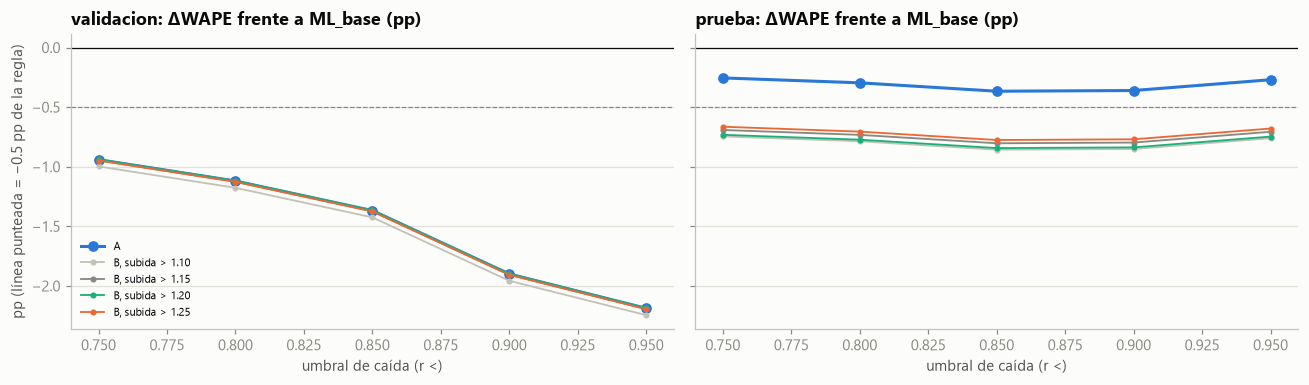

In [ ]:
sen = pd.read_parquet(RES / "regimen_sensibilidad.parquet")
fmt_s = lambda x: x.assign(dWAPE=(x.dWAPE * 100).round(2), dsesgo_abs=(x.dsesgo_abs * 100).round(1),
                           gana=(x.gana * 100).round(0), pct_caida=(x.pct_caida * 100).round(0),
                           pct_subida=(x.pct_subida * 100).round(0))
a = fmt_s(sen[sen.regla == "A"]).pivot(index="bajo", columns="periodo",
                                       values=["dWAPE", "dsesgo_abs", "gana", "adopta", "pct_caida"])
print("Regla A (caída → TD_mix_k3) · dWAPE y dsesgo_abs en pp, gana = % de orígenes:")
print(a.to_string())
for met in ["dWAPE", "adopta"]:
    b = fmt_s(sen[sen.regla == "B"]).pivot_table(index="bajo", columns=["periodo", "alto"], values=met, aggfunc="first")
    print(f"\nRegla B (además subida → TD_mix_k12) · {met}:"); print(b.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a_, p in zip(ax, ["validacion", "prueba"]):
    x = sen[(sen.periodo == p) & (sen.regla == "A")]
    a_.plot(x.bajo, x.dWAPE * 100, marker="o", color=AZUL, lw=2, label="A")
    for alto, c in zip(sorted(sen.alto.dropna().unique()), [GRIS_CLARO, GRIS, COLORES[2], COLORES[1]]):
        y = sen[(sen.periodo == p) & (sen.regla == "B") & (sen.alto == alto)]
        a_.plot(y.bajo, y.dWAPE * 100, marker=".", lw=1.2, color=c, label=f"B, subida > {alto:.2f}")
    a_.axhline(0, color="#0b0b0b", lw=.8); a_.axhline(-.5, color=GRIS, lw=.8, ls="--")
    a_.set_title(f"{p}: ΔWAPE frente a ML_base (pp)"); a_.set_xlabel("umbral de caída (r <)")
ax[0].legend(fontsize=7.5); ax[0].set_ylabel("pp (línea punteada = −0.5 pp de la regla)")
fig.tight_layout(); fig.savefig(FIG / "29_sensibilidad_estado.png"); plt.show()

**Lectura.** El resultado **no depende del corte exacto**:
- **Regla A:** mejora a `ML_base` con cualquier umbral de caída entre 0.75 y 0.95, en los dos periodos (validación −0.9
  a −2.2 pp de WAPE; prueba −0.25 a −0.37 pp) y siempre baja el |sesgo| (−2.5 a −5.2 pp y −0.7 a −1.7 pp). Cumple la
  regla en validación con todos los umbrales; en prueba no llega al −0.5 pp con ninguno.
- **Regla B:** cumple la regla en los **20 pares de umbrales** y en ambos periodos (prueba −0.7 a −0.9 pp; validación
  −0.9 a −2.3 pp). Es casi insensible al umbral de subida (±0.05 pp entre 1.10 y 1.25).
- Umbrales de caída más altos (0.90–0.95) marcan más familias en caída (57–69 % de las filas de validación) y dan más
  ganancia en validación, pero no en prueba: 0.85 queda en medio y es el que se usa.

### 3.8 Propuesta adoptada: `TD_estado`, pronóstico según el estado de la familia (LOG #45)

**Regla.** En cada origen T, para cada familia (venta cruda de todos sus SKUs, solo meses ≤ T):

| r = media 3 meses ≤ T / media de los 12 anteriores | Estado | Pronóstico de los SKUs de la familia |
|---|---|---|
| r < 0.85 | caída | `TD_mix_k3`: volumen = promedio de (nivel de 3 meses × índice) y Σ `ML_base`; reparto con la cuota del ML |
| r > 1.15 | subida | `TD_mix_k12`: igual, con el nivel de 12 meses |
| en medio | estable | `ML_base` |

Implementación: `jerarquico.estado_familia` y `jerarquico.regla_estado`; columna `TD_estado` en
`pronosticos_*_jer.parquet`. Es el pronóstico de los SKUs maduros en inventario (`03_inventario`) y en el pedido
(`src/pedido.py`). Los jóvenes siguen con `Media_post`.

**Por qué.**
1. **Problema que resuelve: el sesgo después de un cambio de nivel.** `ML_base` normaliza con la media de 12 meses, así
   que tras una caída sigue pronosticando el nivel anterior. Su sesgo crece con la duración de la caída: +7 % en los
   meses 1–2, +10 % en los 3–5 y +25 % a partir del 6 (§3.6). Esto pasó en toda la validación (caida_2024): +19 %.
   Un sesgo así se convierte directamente en stock de más.
2. **Mecanismo, no ajuste estadístico.** El nivel de 3 meses de la familia reacciona rápido a una caída, pero tras una
   subida la persigue y se pasa, porque las alzas suelen revertir (como ya se vio en la fase de ciclo de vida de
   `04_segmentacion`). Por eso la regla es **asimétrica**: rápida para bajar, conservadora para subir. En estable no
   hay nada que corregir y se deja el modelo global.
3. **Es causal.** El estado solo usa venta ≤ T (se comprueba abajo perturbando el futuro): en producción se calcula
   igual que en el backtest, con el cierre de cada mes.
4. **Cumple la regla WAPE + sesgo en los dos periodos**, no solo en validación: WAPE 0.456 vs 0.469 (9 de 12 orígenes)
   y 0.482 vs 0.490 (9 de 13), con el sesgo de +19.3 → +15.2 % y de +3.5 → +1.6 %. Ninguna otra variante de este
   proyecto pasó la regla en prueba.
5. **Es robusta a los umbrales (§3.7):** cumple la regla en los 20 pares probados (caída 0.75–0.95, subida 1.10–1.25),
   en ambos periodos. El resultado no depende del corte exacto.
6. **Es simple y explicable:** combina tres modelos que ya existían, sin parámetros nuevos que entrenar. El planeador
   puede ver el estado de cada familia y saber qué pronóstico se usó.

**Riesgos y cómo se vigilan.**
- **La parte de subidas se definió viendo el periodo de prueba** (en validación casi no hubo subidas: A y B dan igual).
  La regla A (solo caídas) sí se justifica solo con validación; B añade 0.5 pp en prueba. Se revisa en cada
  reentrenamiento mensual: si en 6 meses con familias en subida `TD_estado` no le gana a la regla A, se vuelve a A.
- **La ganancia en WAPE es moderada** (0.8–1.3 pp). Lo principal es el sesgo.
- **No ahorra stock con el SS empírico** (`03_inventario`): el SS se calibra con los errores de ventana de cada modelo y
  absorbe el sesgo, así que a igual nivel de servicio el stock queda igual que con `ML_base`. La ventaja es tener un
  pronóstico central más fiel (sesgo +1.6 % en prueba), que es lo que ve comercial y compras.
- **Ningún modelo anticipa un giro en el mismo mes objetivo** (§3.6): la regla corrige *después* de que la caída ya se
  ve en los datos.

In [ ]:
FIN = ["ML_base", "TD_mix_k3", "TD_mix_k12", "TD_estado"]
for n, d in jer.items():
    r = resumen(d, FIN)[["WAPE", "sesgo", "WAPE_total", "sesgo_total", "MASE", "RMSSE"]]
    po = por_origen(d, FIN)
    r["gana_a_ML"] = [f"{(po[m] < po.ML_base).sum()}/{len(po)}" if m != "ML_base" else "" for m in FIN]
    r["cumple regla"] = [adopta(d, m, "ML_base") if m != "ML_base" else "" for m in FIN]
    print(f"\n{n}"); print(r.round(3).to_string())

# leakage: el estado de la familia en el origen no cambia si se altera todo lo posterior al origen
import copy
rng_ = np.random.default_rng(0)
for o in [ft.MESES.get_loc(val.origen.min()), ft.MESES.get_loc(test.origen.max())]:
    d_ = copy.copy(datos); d_.y = datos.y.copy()
    d_.y[:, o + 1:] = rng_.poisson(50, d_.y[:, o + 1:].shape)
    assert (jq.estado_familia(d_)[0].iloc[:o + 1] == jq.estado_familia(datos)[0].iloc[:o + 1]).all().all()
print("\nEstado de la familia sin leakage (futuro perturbado en 2 orígenes): OK")


validación
             WAPE  sesgo  WAPE_total  sesgo_total   MASE  RMSSE gana_a_ML cumple regla
ML_base     0.469  0.193       0.223        0.193  0.788  0.666                       
TD_mix_k3   0.449  0.144       0.198        0.144  0.771  0.659      8/12         True
TD_mix_k12  0.470  0.196       0.228        0.196  0.792  0.668      7/12        False
TD_estado   0.456  0.152       0.204        0.152  0.771  0.659      9/12         True

prueba
             WAPE  sesgo  WAPE_total  sesgo_total   MASE  RMSSE gana_a_ML cumple regla
ML_base     0.490  0.035       0.099        0.035  0.952  0.744                       
TD_mix_k3   0.496  0.043       0.103        0.043  0.944  0.739      6/13        False
TD_mix_k12  0.488  0.043       0.088        0.043  0.952  0.742      7/13        False
TD_estado   0.482  0.016       0.087        0.016  0.942  0.737      9/13         True



Estado de la familia sin leakage (futuro perturbado en 2 orígenes): OK


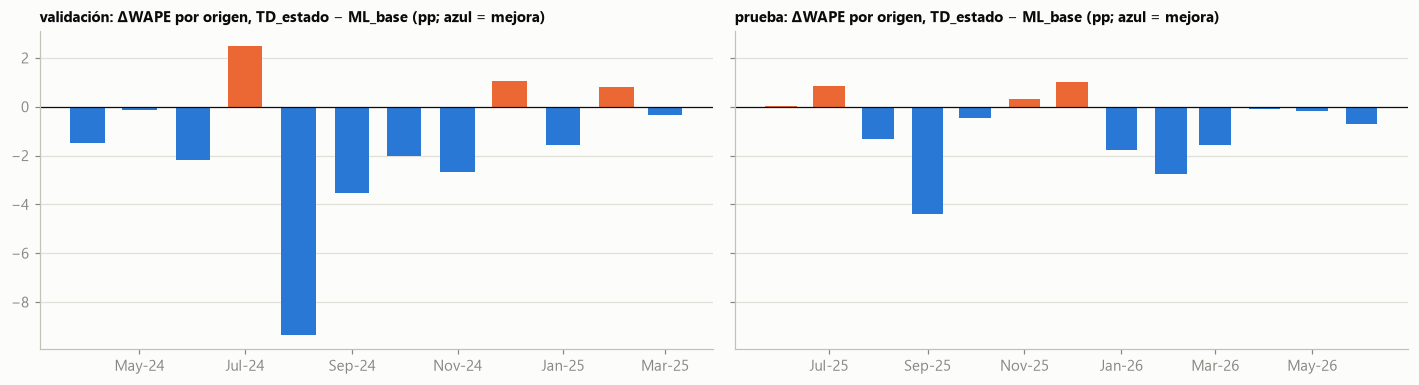


validación: % de unidades reales según el estado de su familia en el origen
origen      Apr-24  May-24  Jun-24  Jul-24  Aug-24  Sep-24  Oct-24  Nov-24  Dec-24  Jan-25  Feb-25  Mar-25
estado_fam                                                                                                
caída         16.0    21.0    23.0    47.0    61.0    47.0    24.0    46.0    70.0    65.0    62.0    18.0
estable       76.0    73.0    71.0    48.0    37.0    49.0    73.0    53.0    27.0    32.0    37.0    80.0
subida         8.0     6.0     6.0     5.0     3.0     4.0     3.0     1.0     3.0     3.0     0.0     1.0

prueba: % de unidades reales según el estado de su familia en el origen
origen      Jun-25  Jul-25  Aug-25  Sep-25  Oct-25  Nov-25  Dec-25  Jan-26  Feb-26  Mar-26  Apr-26  May-26  Jun-26
estado_fam                                                                                                        
caída         35.0     1.0     0.0     0.0     1.0     3.0    33.0    47.0    72.0   

In [ ]:
# por origen: ΔWAPE de TD_estado frente a ML_base y estado de las familias (% de unidades reales)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for a, (n, d) in zip(ax, jer.items()):
    po = por_origen(d, ["ML_base", "TD_estado"])
    dw = (po.TD_estado - po.ML_base) * 100
    a.bar(po.index, dw, width=20, color=[AZUL if v < 0 else COLORES[1] for v in dw])
    a.axhline(0, color="#0b0b0b", lw=.8)
    a.set_title(f"{n}: ΔWAPE por origen, TD_estado − ML_base (pp; azul = mejora)", fontsize=10)
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
fig.tight_layout(); fig.savefig(FIG / "30_td_estado_por_origen.png"); plt.show()
for n, d in jer.items():
    mix = d.groupby(["origen", "estado_fam"]).y.sum().unstack(fill_value=0)
    mix = (mix.div(mix.sum(axis=1), axis=0) * 100).round(0)
    mix.index = mix.index.strftime("%b-%y")
    print(f"\n{n}: % de unidades reales según el estado de su familia en el origen"); print(mix.T.to_string())

In [ ]:
# dentro de cada estado y por segmento: ¿a quién mejora y a quién no?
for n, d in jer.items():
    r = pd.concat({e: resumen(g, ["ML_base", "TD_estado"])[["WAPE", "sesgo"]].unstack() for e, g in d.groupby("estado_fam")},
                  axis=1).T
    print(f"\n{n}, por estado de la familia:"); print(r.round(3).to_string())
t3 = jer["prueba"].merge(clas, on="id_articulo", how="left")
t3["abc"] = t3.abc.astype(object).fillna("sin_ABC")
for col in ["clase", "abc"]:
    r = pd.concat({k_: resumen(g, ["ML_base", "TD_estado"])[["WAPE", "sesgo"]].unstack() for k_, g in t3.groupby(col)},
                  axis=1).T
    print(f"\nprueba, por {col}:"); print(r.round(3).to_string())


validación, por estado de la familia:
           WAPE             sesgo          
        ML_base TD_estado ML_base TD_estado
caída     0.521     0.488   0.197     0.099
estable   0.412     0.412   0.188     0.188
subida    0.742     0.741   0.218     0.206

prueba, por estado de la familia:
           WAPE             sesgo          
        ML_base TD_estado ML_base TD_estado
caída     0.503     0.489   0.036    -0.027
estable   0.457     0.457   0.052     0.052
subida    0.540     0.523   0.002    -0.009

prueba, por clase:
                WAPE             sesgo          
             ML_base TD_estado ML_base TD_estado
errática       0.600     0.590   0.008    -0.015
grumosa        0.849     0.841  -0.100    -0.120
intermitente   0.892     0.885  -0.253    -0.274
suave          0.410     0.403   0.055     0.040



prueba, por abc:
           WAPE             sesgo          
        ML_base TD_estado ML_base TD_estado
A         0.434     0.424   0.060     0.040
B         0.584     0.581  -0.026    -0.042
C         0.821     0.816  -0.074    -0.088
sin_ABC   0.996     0.996  -0.527    -0.535


## 4. Prueba (sep-2025 → sep-2026)

In [ ]:
FINALES = ["Naive", "SNaive", "MA12", "ETS", "SARIMA_fam", "Croston", "SBA", "TSB", "Ruta_clasica", "ML_base", "ML_devol",
           "ML_sin_limpieza", mejor_ml]
FINALES = list(dict.fromkeys(FINALES))
tabla(test, FINALES)

,MASE,RMSSE,WAPE,relMAE,sesgo,MAPE_y>0,WAPE_total,sesgo_total
ML_sin_limpieza,0.944,0.740,48.9%,0.816,+2.9%,184%,10.1%,+2.9%
ML_devol,0.951,0.743,48.9%,0.817,+3.7%,185%,9.4%,+3.7%
ML_base,0.952,0.744,49.0%,0.818,+3.5%,185%,9.9%,+3.5%
MA12,0.971,0.753,49.7%,0.829,+3.7%,193%,10.7%,+3.7%
Ruta_clasica,0.953,0.753,49.7%,0.829,+1.7%,197%,11.2%,+1.7%
SBA,1.053,0.787,50.0%,0.834,+2.0%,202%,11.2%,+2.0%
TSB,0.995,0.755,51.2%,0.854,+7.0%,211%,11.9%,+7.0%
Croston,1.073,0.794,51.6%,0.860,+7.4%,214%,12.0%,+7.4%
SARIMA_fam,0.957,0.758,53.1%,0.885,+11.3%,200%,13.2%,+11.3%
ETS,1.015,0.786,57.1%,0.953,+10.9%,214%,12.3%,+10.9%


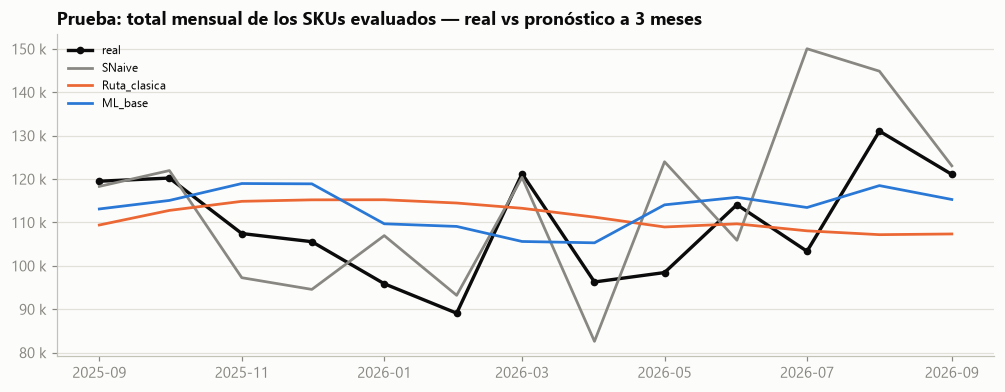

mes_obj          2025-09-01  2025-10-01  2025-11-01  2025-12-01  2026-01-01  2026-02-01  2026-03-01  2026-04-01  2026-05-01  2026-06-01  2026-07-01  2026-08-01  2026-09-01
Naive                 -13.2        23.3        32.3        14.3        25.8        21.5       -12.6         0.2        -9.0         6.8        -6.1       -24.5        -5.4
SNaive                 -1.0         1.4        -9.5       -10.4        11.6         4.6        -0.7       -14.2        25.9        -7.2        45.2        10.5         1.6
MA12                   -9.9        -7.5         4.7         7.0        17.8        28.2        -4.9        19.0        16.2         0.4        12.1       -12.9        -5.1
ETS                     1.3        27.7        18.6        25.1        21.0        31.4        -6.4        12.8        13.8        -0.2         9.0        -0.1        -1.4
SARIMA_fam              0.3         9.0        10.7        19.8        29.8        40.3         2.7        22.2        20.2         3.9     

In [ ]:
tot = test.groupby("mes_obj")[["y"] + FINALES].sum()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tot.index, tot.y, color="#0b0b0b", lw=2.2, marker="o", ms=4, label="real")
for m, col in zip(["SNaive", "Ruta_clasica", mejor_ml], [GRIS, COLORES[1], AZUL]):
    ax.plot(tot.index, tot[m], color=col, lw=1.8, label=m)
ax.yaxis.set_major_formatter(FMT_MILES); ax.legend(fontsize=8)
ax.set_title(f"Prueba: total mensual de los SKUs evaluados — real vs pronóstico a {H} meses")
fig.savefig(FIG / "20_prueba_total.png"); plt.show()
print((tot[FINALES].sub(tot.y, axis=0).div(tot.y, axis=0) * 100).round(1).T.to_string())

### 4.1 Prueba por segmento

In [ ]:
t2 = test.merge(clas, on="id_articulo", how="left")
t2["abc"] = t2.abc.astype(object).fillna("sin_ABC")
for col in ["tipo", "clase", "abc", "perfil"]:
    r = pd.concat({k: resumen(g, ["SNaive", "Ruta_clasica", mejor_ml]).WAPE for k, g in t2.groupby(col)}, axis=1)
    peso = t2.groupby(col).y.sum() / t2.y.sum()
    print(f"\nWAPE por {col} (fila 'peso' = % de unidades reales):")
    print(pd.concat([r, peso.rename("peso").to_frame().T]).round(3).to_string())


WAPE por tipo (fila 'peso' = % de unidades reales):
               base  proyecto (proxy)
SNaive        0.593             1.070
Ruta_clasica  0.492             0.867
ML_base       0.485             0.851
peso          0.987             0.013

WAPE por clase (fila 'peso' = % de unidades reales):
              errática  grumosa  intermitente  suave
SNaive           0.750    1.070         1.064  0.489
Ruta_clasica     0.626    0.862         1.028  0.404
ML_base          0.600    0.849         0.892  0.410
peso             0.393    0.013         0.000  0.594



WAPE por abc (fila 'peso' = % de unidades reales):
                  A      B      C  sin_ABC
SNaive        0.526  0.731  1.011    1.051
Ruta_clasica  0.431  0.604  0.890    1.963
ML_base       0.434  0.584  0.821    0.996
peso          0.758  0.157  0.084    0.000



WAPE por perfil (fila 'peso' = % de unidades reales):
              enterprise  home_office  mixto  no_producto
SNaive             0.630        0.528  0.663        0.126
Ruta_clasica       0.522        0.445  0.540        0.130
ML_base            0.505        0.441  0.545        0.110
peso               0.376        0.370  0.251        0.003


### 4.2 Real vs pronóstico del sistema, por clase ABC (prueba)

El pronóstico que usa la política de pedidos (`03_inventario`): `TD_estado` para los maduros (§3.8) y `Media_post`
para los jóvenes (sección 5), emitido 3 meses antes. La ruta clásica (con los mismos jóvenes) va de referencia. La clase es el
**ABC móvil al origen** (`04_segmentacion`, LOG #31). En el título: sesgo del año y error mensual
(Σ|pronóstico − real| / Σ real de los totales mensuales, no a nivel SKU).

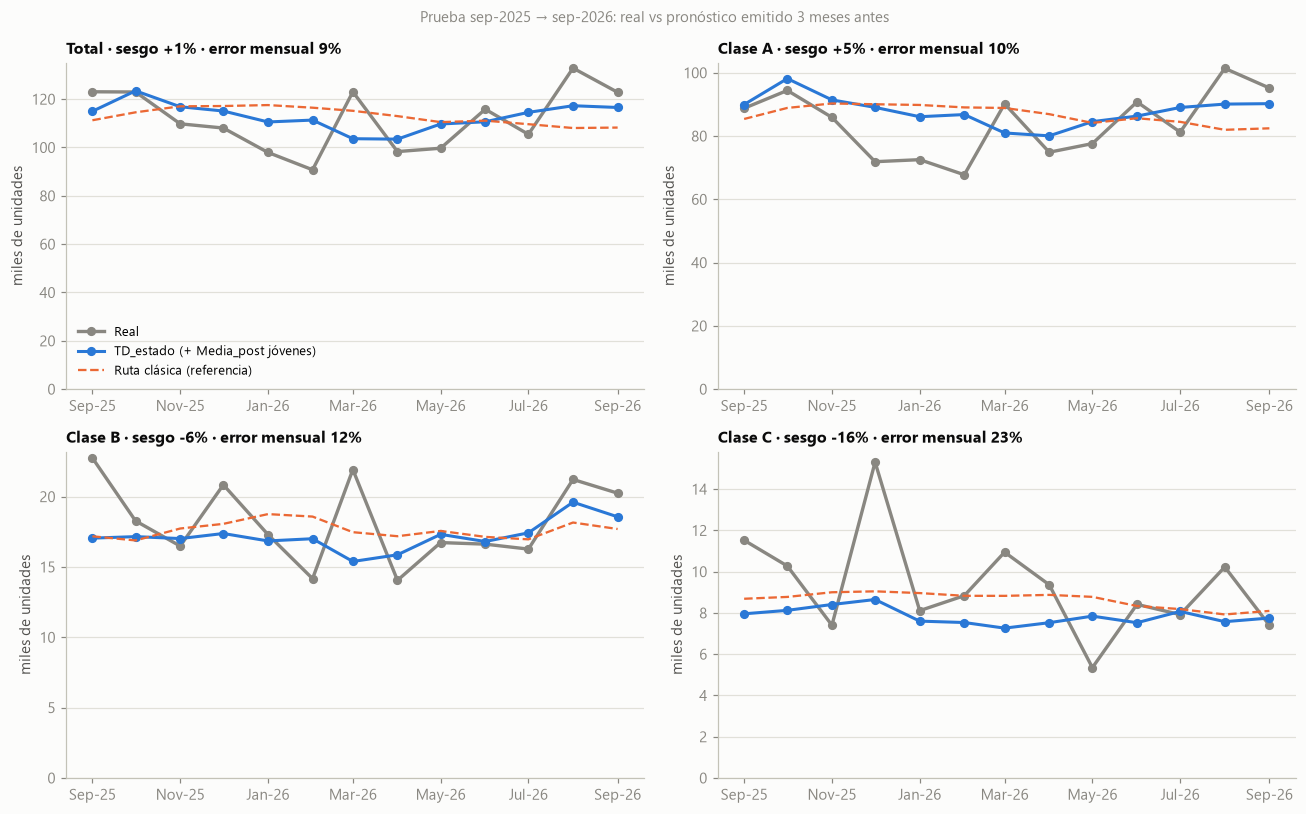

Miles de unidades; dif = pronóstico / real − 1
         Total                 Clase A                 Clase B                 Clase C                
             y TD_estado   dif       y TD_estado   dif       y TD_estado   dif       y TD_estado   dif
mes_obj                                                                                               
Sep-25   123.0     115.0   -7%    88.8      90.0   +1%    22.7      17.0  -25%    11.5       8.0  -31%
Oct-25   122.9     123.4   +0%    94.4      98.1   +4%    18.3      17.2   -6%    10.3       8.1  -21%
Nov-25   109.8     116.8   +6%    85.9      91.4   +6%    16.5      17.0   +3%     7.4       8.4  +14%
Dec-25   108.0     115.1   +7%    71.9      89.0  +24%    20.8      17.4  -17%    15.3       8.6  -44%
Jan-26    97.9     110.5  +13%    72.5      86.1  +19%    17.3      16.8   -3%     8.1       7.6   -6%
Feb-26    90.8     111.3  +23%    67.8      86.8  +28%    14.2      17.0  +20%     8.8       7.5  -15%
Mar-26   123.0     103.6  

In [ ]:
jov = pd.read_parquet(RES / "cold_jovenes_prueba.parquet")[["id_articulo", "origen", "mes_obj", "y", "Media_post"]]
sis = pd.concat([jer["prueba"][["id_articulo", "origen", "mes_obj", "y", "TD_estado", "Ruta_clasica"]],
                 jov.assign(TD_estado=jov.Media_post, Ruta_clasica=jov.Media_post).drop(columns="Media_post")])
abc_mov = pd.read_parquet(RAIZ / "data" / "processed" / "segmentacion_sku_mes.parquet", columns=["id_articulo", "mes", "abc_movil"])
sis = sis.merge(abc_mov.rename(columns={"mes": "origen"}), on=["id_articulo", "origen"], how="left")

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
tablas = {}
for a, (tit, x) in zip(ax.ravel(), [("Total", sis)] + [(f"Clase {c}", sis[sis.abc_movil == c]) for c in "ABC"]):
    g = x.groupby("mes_obj")[["y", "TD_estado", "Ruta_clasica"]].sum() / 1e3
    a.plot(g.index, g.y, lw=2.2, marker="o", ms=5, color=GRIS, label="Real")
    a.plot(g.index, g.TD_estado, lw=2, marker="o", ms=5, color=AZUL, label="TD_estado (+ Media_post jóvenes)")
    a.plot(g.index, g.Ruta_clasica, lw=1.5, ls="--", color=COLORES[1], label="Ruta clásica (referencia)")
    sesgo = g.TD_estado.sum() / g.y.sum() - 1
    err = (g.TD_estado - g.y).abs().sum() / g.y.sum()
    a.set_title(f"{tit} · sesgo {sesgo:+.0%} · error mensual {err:.0%}", fontsize=10.5)
    a.set_ylim(0, None)
    a.set_ylabel("miles de unidades")
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
    tablas[tit] = g.assign(dif=g.TD_estado / g.y - 1)
ax[0, 0].legend(fontsize=8.5, loc="lower left")
fig.suptitle(f"Prueba sep-2025 → sep-2026: real vs pronóstico emitido {H} meses antes", fontsize=10, color=GRIS)
fig.tight_layout()
fig.savefig(FIG / "25_real_vs_pronostico_prueba.png"); plt.show()

t = pd.concat({k: v[["y", "TD_estado", "dif"]] for k, v in tablas.items()}, axis=1)
t.index = t.index.strftime("%b-%y")
fmt = t.copy()
for c in fmt.columns:
    fmt[c] = t[c].map(lambda v: f"{v:+.0%}" if c[1] == "dif" else f"{v:.1f}")
print("Miles de unidades; dif = pronóstico / real − 1")
print(fmt.to_string())

**Lectura.** El total queda **+1 %** en el año, con un error mensual del 9 %: a nivel agregado los errores de los SKUs
se compensan. El pronóstico es mucho **más plano** que la venta real (103–123 contra 91–133 mil u./mes): a 3 meses
capta el nivel y algo de estacionalidad, pero no los picos de cada mes, que se cubren con el SS (`03_inventario`).
El error más grande es el **sesgo de dic-2025 a feb-2026 en la clase A** (+24 %, +19 %, +28 %): el modelo repitió
un repunte estacional que este año no ocurrió. Los meses más bajos del pronóstico frente a la venta son mar-2026
(−16 %) y ago-2026 (−12 %), picos que a 3 meses no se ven venir. En C sub-pronostica (−16 % en el año) y no capta los
pedidos grandes y esporádicos (dic-2025: 15 mil reales contra 9 mil), típicos de la demanda grumosa.

### 4.3 XGBoost por serie, top 30 SKUs y top 30 familias (`notebooks/XGBoost.py`, LOG #33)

Adaptación del script de XGBoost del usuario: un `XGBRegressor` por serie (100 árboles, profundidad 3, error
cuadrático), con features = mes + 3 lags. Con h = 3 los lags son 3, 4 y 5. Los datos vienen del panel (`fechafactura`,
`Venta Producto`). Top 30 por unidades del último año. Se evalúa con el **mismo walk-forward** (entrena con datos
≤ T, pronostica T + 3) y se compara contra los nuestros (`src/comparar_xgb.py`):
- **SKU:** pares (SKU, origen) del set evaluado.
- **Familia:** real = total de la familia. Lo nuestro se suma por familia: maduros + jóvenes (`Media_post`).

MAE y RMSE están en unidades; R² fuera de muestra = 1 − SSE / SST de los reales del periodo.

In [ ]:
import comparar_xgb as cx

XG = cx.NUESTROS + ["XGBoost"]
sku = cx.nivel_sku()
fam, _ = cx.nivel_familia()
for nivel, res in [("Top 30 SKUs", sku), ("Top 30 familias", fam)]:
    for p, d in res.items():
        print(f"\n{nivel} · {p} ({d.id_articulo.nunique()} series, {len(d)} pares serie-origen)")
        print(cx.tabla(d, XG).sort_values("WAPE").round(3).to_string())

ins = pd.concat([pd.read_csv(RES / f"xgb_top30_insample_{n}.csv") for n in ("sku", "familia")])
print("\nXGBoost in-sample (como el script original): mediana por nivel")
print(ins.groupby("nivel")[["R2", "wMAPE", "sMAPE"]].median().round(3).to_string())


Top 30 SKUs · validacion (30 series, 360 pares serie-origen)
               MASE   WAPE  sesgo       MAE      RMSE  sMAPE     R2
Ruta_clasica  0.723  0.318  0.133   614.338   903.806  0.352  0.639
TD_estado     0.778  0.342  0.161   659.759   970.795  0.358  0.583
ML_base       0.801  0.352  0.199   679.740   995.666  0.369  0.561
MA12          0.816  0.360  0.204   695.167  1054.395  0.370  0.508
XGBoost       0.989  0.460  0.246   889.035  2452.477  0.402 -1.661
SNaive        1.278  0.570  0.354  1101.536  2789.617  0.464 -2.442

Top 30 SKUs · prueba (30 series, 390 pares serie-origen)
               MASE   WAPE  sesgo       MAE      RMSE  sMAPE     R2
Ruta_clasica  0.959  0.396  0.021   772.322  1217.133  0.432  0.381
TD_estado     0.955  0.397  0.031   772.921  1234.771  0.428  0.363
MA12          0.975  0.402  0.050   783.844  1224.456  0.435  0.374
ML_base       0.977  0.406  0.050   791.736  1245.288  0.435  0.353
SNaive        1.114  0.464  0.060   904.113  1447.022  0.472  0.

**Lectura.**
- **XGBoost por serie queda último o penúltimo** en los dos niveles; solo le gana a SNaive en validación. En los top 30
  SKUs su WAPE es 0.460 en validación y 0.604 en prueba, contra 0.32–0.36 y 0.40–0.41 de los nuestros. En las
  familias queda en 0.360 y 0.319, contra 0.25–0.28 y 0.22–0.23. Además sobre-pronostica mucho más (+14 a +26 %).
- **El R² in-sample engaña.** Ajustado sobre su propia historia, como en el script original, da un R² mediano de
  0.87–0.89 y un wMAPE de 10–12 %. Fuera de muestra, el R² de los SKUs cae a −1.7 en validación y a −3.4 en prueba
  (algunos SKUs con pronósticos muy altos, como el 1978). Un modelo de 100 árboles por serie, con unos 100 meses de
  datos, **memoriza** la historia en lugar de aprender un patrón que se repita. Por eso todo se evalúa con
  walk-forward.
- La diferencia no es XGBoost contra HistGradientBoosting (son el mismo tipo de algoritmo). Es **un modelo por
  serie contra uno global**: el global aprende de ~800 SKUs a la vez, con features normalizadas y pérdida Poisson.
- **En los 30 SKUs más grandes, los clásicos están a la par del ML:** la ruta clásica es la mejor en validación
  (WAPE 0.318) y empata con `TD_estado` en prueba (0.396 vs 0.397). Es coherente con lo visto por ABC: la ventaja del
  ML está en la cola de SKUs chicos e intermitentes. `TD_estado` mejora a `ML_base` en los cuatro cortes (SKU y
  familia, validación y prueba) y es el mejor en las top 30 familias de prueba (0.219).

### 4.4 Top 30: real contra cada pronóstico, y qué mide realmente el R²

**Qué es el R².** R² = 1 − SSE / SST, donde SSE = Σ(pronóstico − real)² y SST = Σ(real − media del real)².
Compara el modelo contra un pronóstico "tonto": **una línea constante en la media real del periodo**.
- R² = 1: error cero. R² = 0: igual que esa línea constante. **R² < 0: peor que la línea constante.**
- Esa línea es tramposa, porque usa la media **real** del periodo, que no se conoce de antemano. Un R² negativo
  fuera de muestra no es raro en pronóstico: ganarle a la media real de un futuro que no has visto es difícil.

**Por qué el R² del script original salía tan alto (~0.9).**
1. **In-sample:** el modelo se evaluaba sobre los mismos meses con que se entrenó. Con 100 árboles de profundidad 3
   y ~100 meses por serie, el modelo puede aprenderse cada pico de memoria. El R² mide memoria, no pronóstico.
2. **Con lags 1–3 (horizonte 1),** el mes anterior explica mucho. A 3 meses de distancia esa información no existe.

**Por qué el R² agrupado de varias series engaña.** Si se juntan series de distinto tamaño (un SKU de 5,000 u./mes
con uno de 500), casi toda la varianza (SST) está **entre** series, no dentro de cada una. Cualquier pronóstico
que adivine el tamaño de cada SKU obtiene un R² alto aunque no capte ningún movimiento mes a mes. La tabla de
abajo lo mide con un **oráculo** que predice, para cada serie, su propia media real del periodo (una constante): ese
oráculo saca un R² agrupado alto, pero 0 dentro de cada serie por definición. Por eso las familias (tamaños muy
distintos) tienen R² de 0.85–0.89 y los SKUs del top 30 (tamaños más parecidos) solo 0.35–0.64.

**El R² por serie** (dentro de cada SKU, sobre los 12–13 meses del periodo) dice cuánto del movimiento mes a mes
explica el pronóstico. A 3 meses suele ser ≤ 0: los pronósticos son mucho más planos que la venta real (sección 4.2),
y los picos se cubren con stock de seguridad, no con el pronóstico. Por esto el proyecto decide con **WAPE + sesgo**:
el WAPE pondera por volumen (lo que cuesta en inventario), no eleva al cuadrado los picos, se entiende en negocio y es
comparable con los demás equipos; el sesgo vigila el error sistemático que se convierte en stock de más o de menos.
El MASE (contra el seasonal naive in-sample) se reporta como secundaria porque no lo dominan los SKUs grandes.

In [ ]:
MOD30 = [cx.TD, "ML_base", "Ruta_clasica", "MA12", "SNaive", "XGBoost"]
for nivel, res in [("Top 30 SKUs", sku), ("Top 30 familias", fam)]:
    for p, d in res.items():
        print(f"\n{nivel} · {p}")
        print(cx.r2_descompuesto(d, MOD30).round(3).to_string())


Top 30 SKUs · validacion


              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_estado           0.583                -0.469          0.967
ML_base             0.561                -0.534          0.933
Ruta_clasica        0.639                -0.199          1.000
MA12                0.508                -0.394          0.933
SNaive             -2.442                -2.556          1.000
XGBoost            -1.661                -0.860          0.967
oráculo             0.763                 0.000          0.000

Top 30 SKUs · prueba


              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_estado           0.363                -0.156          0.833
ML_base             0.353                -0.214          0.900
Ruta_clasica        0.381                -0.136          0.967
MA12                0.374                -0.140          0.933
SNaive              0.126                -0.669          0.933
XGBoost            -3.393                -0.762          0.900
oráculo             0.475                 0.000          0.000

Top 30 familias · validacion


              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_estado           0.870                -0.615          0.933
ML_base             0.859                -0.619          0.967
Ruta_clasica        0.892                -0.288          0.967
MA12                0.846                -0.540          1.000
SNaive              0.398                -1.876          0.933
XGBoost             0.721                -2.149          0.967
oráculo             0.935                 0.000          0.000

Top 30 familias · prueba


              R2_agrupado  R2_por_serie_mediana  %_series_R2<0
TD_estado           0.883                -0.153          0.800
ML_base             0.876                -0.140          0.833
Ruta_clasica        0.875                -0.204          1.000
MA12                0.870                -0.159          0.900
SNaive              0.812                -0.901          0.967
XGBoost             0.788                -0.860          0.933
oráculo             0.894                 0.000          0.000


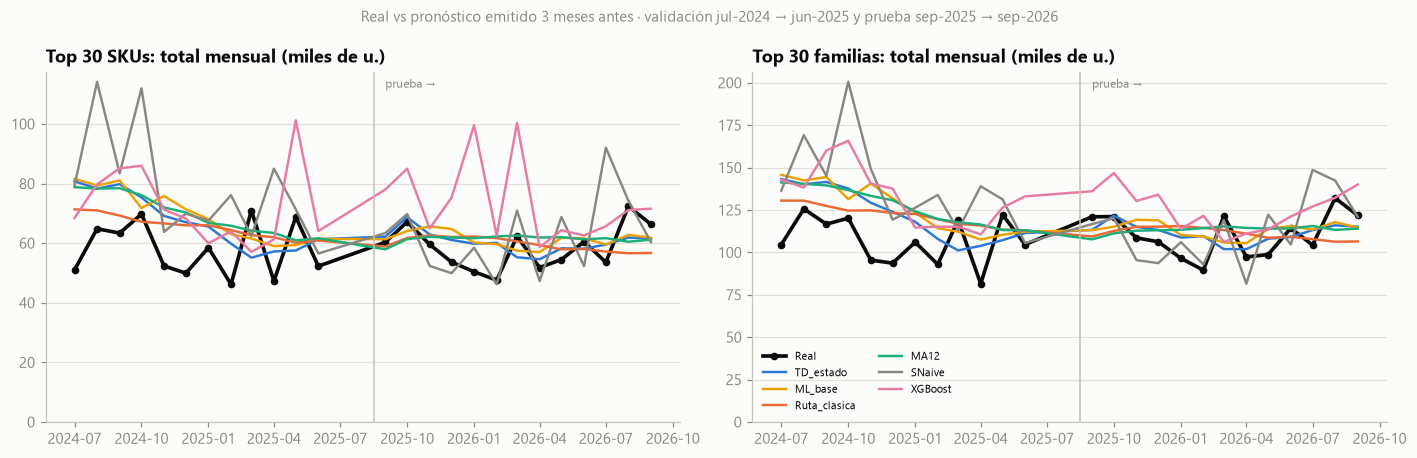

In [ ]:
COL30 = dict(zip(MOD30, [AZUL, COLORES[3], COLORES[1], COLORES[2], GRIS, COLORES[4]]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, (nivel, res) in zip(ax, [("Top 30 SKUs", sku), ("Top 30 familias", fam)]):
    d = pd.concat(res.values())
    tot = d.groupby("mes_obj")[["y"] + MOD30].sum() / 1e3
    a.plot(tot.index, tot.y, color="#0b0b0b", lw=2.4, marker="o", ms=4, label="Real")
    for m in MOD30:
        a.plot(tot.index, tot[m], color=COL30[m], lw=1.6, label=m)
    a.axvline(pd.Timestamp("2025-08-16"), color=GRIS_CLARO, lw=1)
    a.text(pd.Timestamp("2025-09-01"), a.get_ylim()[1] * .98, "prueba →", fontsize=8, color=GRIS, va="top")
    a.set_ylim(0, None)
    a.set_title(f"{nivel}: total mensual (miles de u.)")
ax[1].legend(fontsize=7.5, ncol=2, loc="lower left")
fig.suptitle(f"Real vs pronóstico emitido {H} meses antes · validación jul-2024 → jun-2025 y prueba sep-2025 → sep-2026",
             fontsize=9.5, color=GRIS)
fig.tight_layout()
fig.savefig(FIG / "26_top30_total.png"); plt.show()

Por SKU (los 30, ordenados por venta del último año). Para que se lea, cada panel muestra el real, el modelo elegido
(`TD_estado`), la ruta clásica y XGBoost; los demás están en la tabla y en el CSV. La escala vertical es propia de
cada panel.

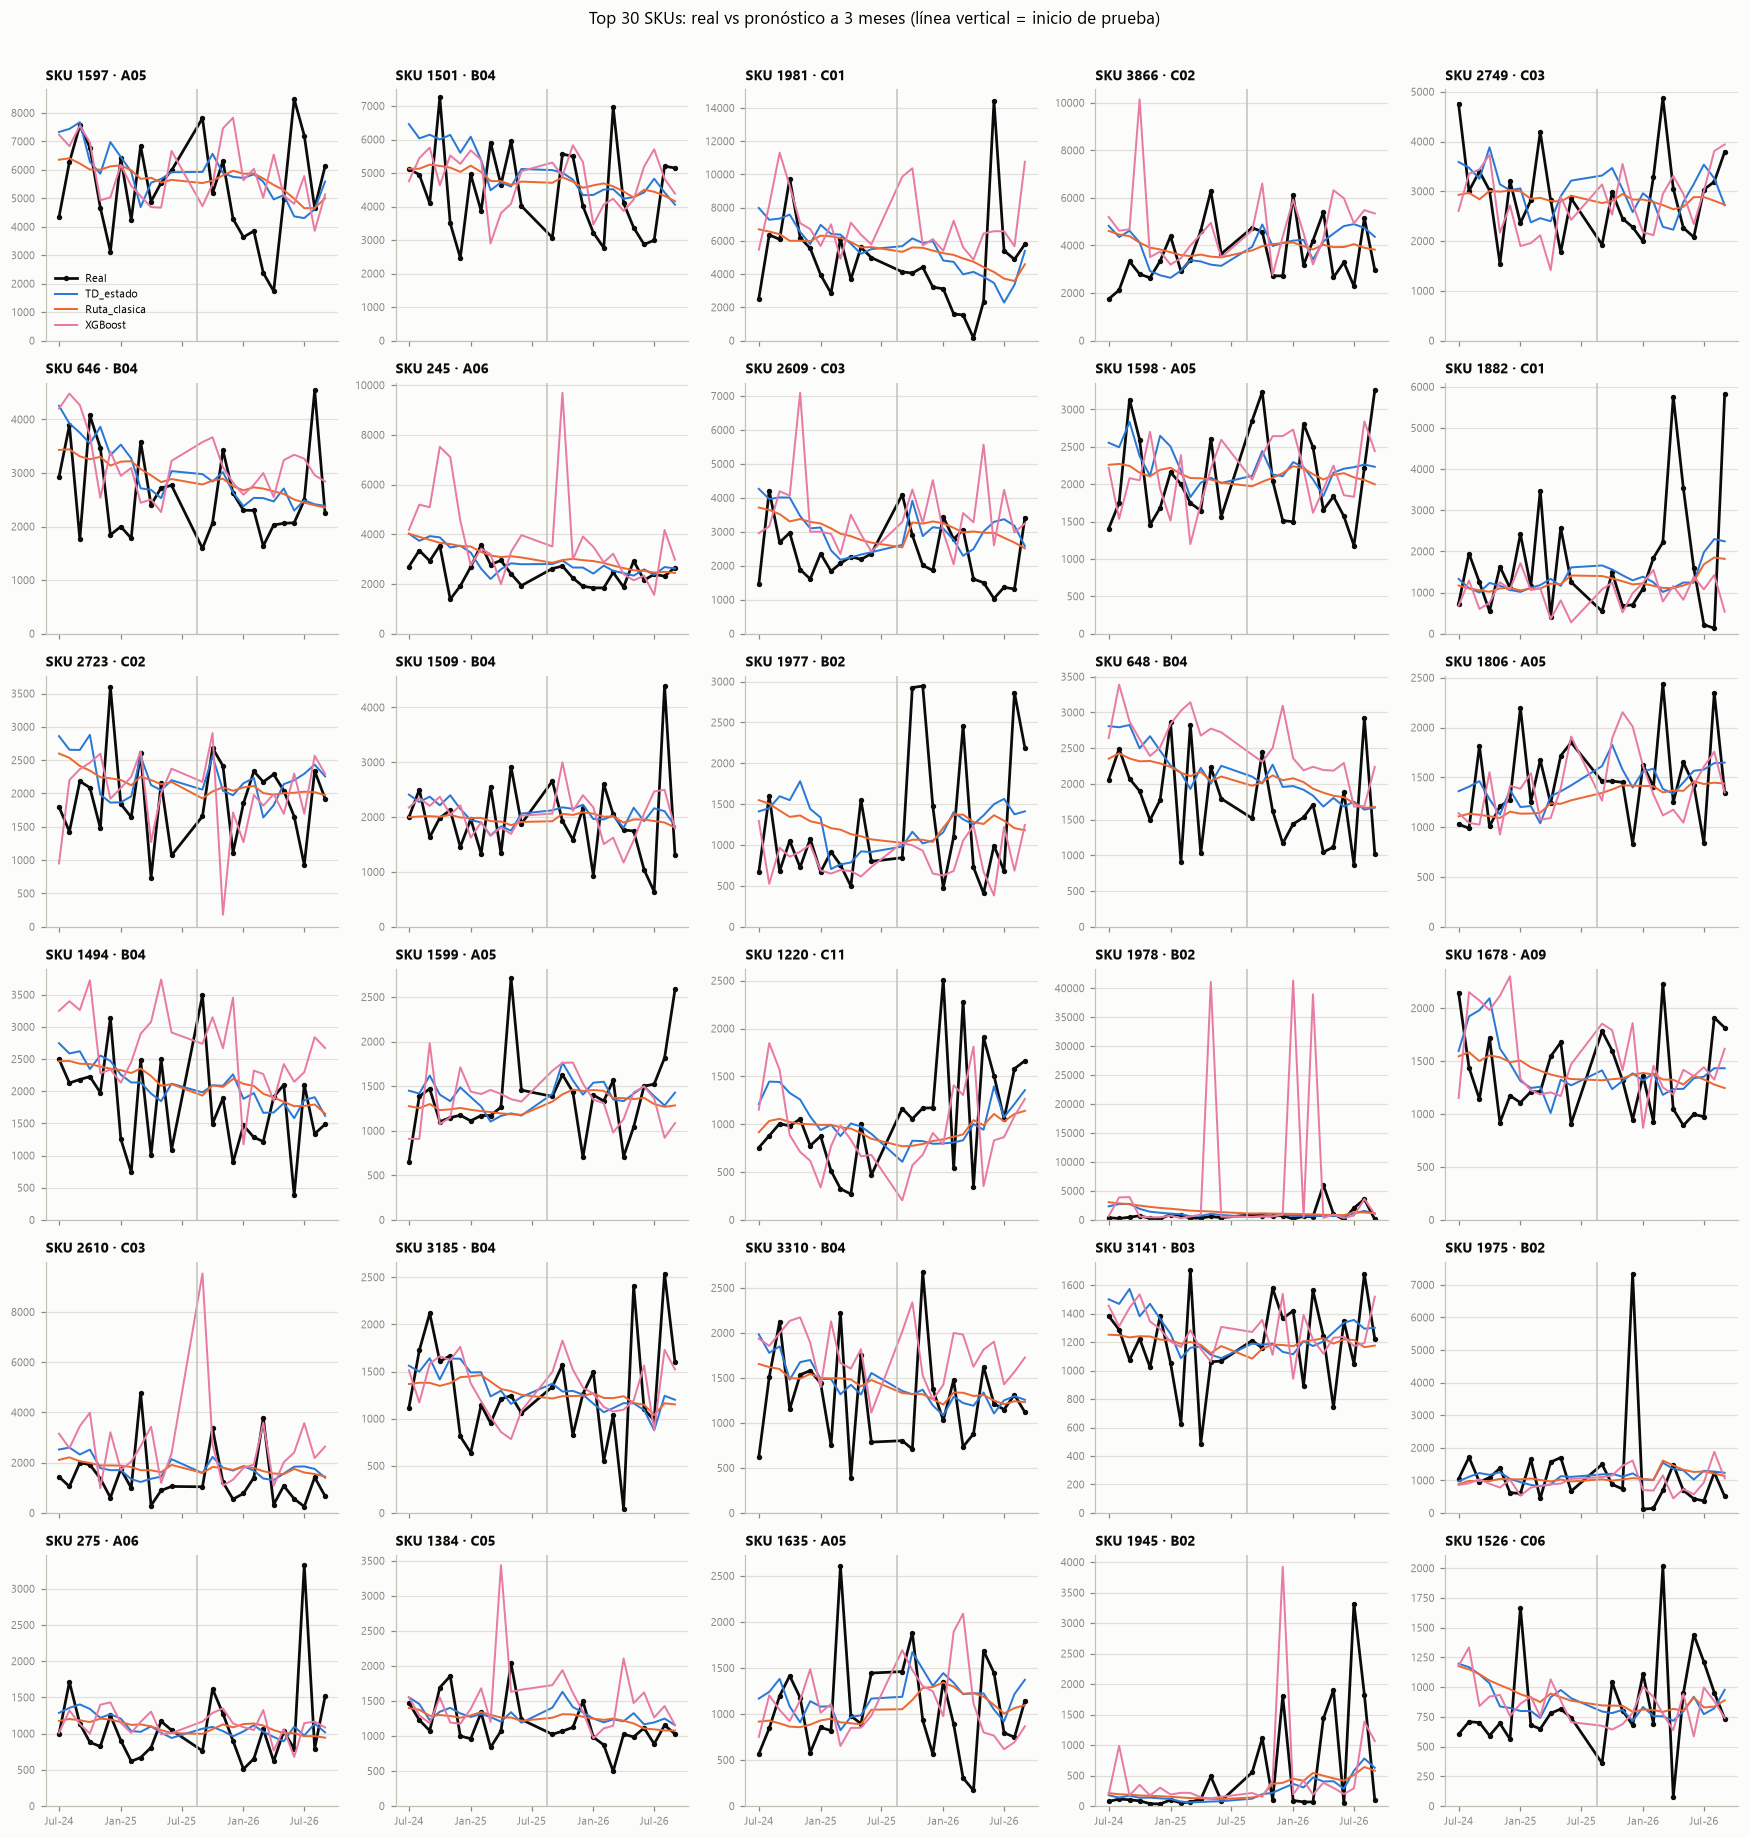

In [ ]:
d = pd.concat(sku.values())
orden = d[d.mes_obj >= "2025-10-01"].groupby("id_articulo").y.sum().sort_values(ascending=False).index
fig, ax = plt.subplots(6, 5, figsize=(16, 17), sharex=True)
for a, s in zip(ax.ravel(), orden):
    g = d[d.id_articulo == s].sort_values("mes_obj")
    a.plot(g.mes_obj, g.y, color="#0b0b0b", lw=1.8, marker="o", ms=2.5, label="Real")
    for m in [cx.TD, "Ruta_clasica", "XGBoost"]:
        a.plot(g.mes_obj, g[m], color=COL30[m], lw=1.3, label=m)
    a.axvline(pd.Timestamp("2025-08-16"), color=GRIS_CLARO, lw=1)
    a.set_ylim(0, None)
    a.set_title(f"SKU {s} · {g.familia.iloc[0]}", fontsize=9)
    a.tick_params(labelsize=7)
    a.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 7]))
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
ax[0, 0].legend(fontsize=7)
fig.suptitle(f"Top 30 SKUs: real vs pronóstico a {H} meses (línea vertical = inicio de prueba)", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, .975])
fig.savefig(FIG / "27_top30_por_sku.png"); plt.show()

**Cuánto predijo cada modelo para cada SKU en el año de prueba** (sep-2025 → sep-2026, 13 meses; unidades
totales del periodo). La columna `mejor` es el modelo con menor error absoluto mensual acumulado del SKU, no el más
cercano en el total: un modelo puede acertar el total del año compensando errores de meses distintos. El detalle
mes a mes de ambos periodos queda en `reports/top30_real_vs_pronosticos.csv`.

In [ ]:
det = pd.concat(sku, names=["periodo"]).reset_index(level=0)[["periodo", "id_articulo", "familia", "origen", "mes_obj", "y"] + MOD30]
det.round(1).to_csv(RAIZ / "reports" / "top30_real_vs_pronosticos.csv", index=False, encoding="utf-8-sig")

pr = sku["prueba"]
tot = pr.groupby("id_articulo")[["y"] + MOD30].sum().reindex(orden)
mae = pr.assign(**{m: (pr[m] - pr.y).abs() for m in MOD30}).groupby("id_articulo")[MOD30].sum().reindex(orden)
tot.insert(0, "familia", pr.groupby("id_articulo").familia.first().reindex(orden))
tot["mejor"] = mae.idxmin(axis=1)
tot.loc["TOTAL"] = ["", *tot[["y"] + MOD30].sum(), ""]
out = tot.copy()
for m in ["y"] + MOD30:
    out[m] = tot[m].map(lambda v: f"{v:,.0f}")
for m in MOD30:
    out[f"{m} %"] = (tot[m].astype(float) / tot.y.astype(float) - 1).map(lambda v: f"{v:+.0%}")
out = out.rename(columns={"y": "real"})
out.round(0).to_csv(RAIZ / "reports" / "top30_totales_prueba.csv", encoding="utf-8-sig")
print(out[["familia", "real"] + MOD30 + ["mejor"]].to_string())
print()
print("Diferencia del total del año vs real:")
print(out[[f"{m} %" for m in MOD30]].to_string())
print()
print("SKUs donde cada modelo es el mejor (menor Σ|error| mensual):", tot.mejor.iloc[:-1].value_counts().to_dict())

            familia     real TD_estado  ML_base Ruta_clasica     MA12   SNaive  XGBoost         mejor
id_articulo                                                                                          
1597            A05   66,633    70,224   73,095       70,419   73,109   78,436   73,421     TD_estado
1501            B04   54,790    58,849   59,404       58,944   60,424   60,191   61,313     TD_estado
1981            C01   55,101    59,718   60,429       62,506   62,684   73,003   91,215          MA12
3866            C02   50,031    56,260   56,766       51,529   54,518   53,060   64,387  Ruta_clasica
2749            C03   37,214    38,116   38,705       36,320   37,770   37,716   38,550          MA12
646             B04   31,388    33,691   34,001       34,379   34,523   35,073   39,745     TD_estado
245             A06   29,967    33,796   34,482       35,402   34,832   36,515   45,263     TD_estado
2609            C03   30,403    38,614   39,220       38,687   40,378   39,832   4

## 5. Cold start (`src/cold_start.py`, LOG #24)

Lo que queda fuera del set maduro, en dos segmentos:
- **Jóvenes** (0–11 meses de vida en el origen): baselines simples contra un modelo global propio (`ML_joven`).
  Se mide WAPE, sesgo y error en log, con la misma regla de adopción WAPE + sesgo (`metricas.adopta`).
- **Pre-lanzamiento** (lanzan entre T+1 y T+3): regla de análogos (familia → sublínea → banda de precio) con rango
  p25–p75 / p10–p90. Supone que el lanzamiento se conoce por comercial.

In [ ]:
import cold_start as cs
jv = {p: pd.read_parquet(RES / f"cold_jovenes_{p}.parquet") for p in ["validacion", "prueba"]}
MJ = cs.BASELINES + ["ML_joven"]
FMTJ = {"WAPE": "{:.3f}", "sesgo": "{:+.1%}", "MAE_log": "{:.3f}", "WAPE_total": "{:.1%}", "sesgo_total": "{:+.1%}"}
for p, d in jv.items():
    print(f"{p}: {len(d):,} filas · {d.id_articulo.nunique()} SKUs · {d.y.sum():,.0f} u.")
pd.concat({p: cs.resumen_joven(d, MJ) for p, d in jv.items()}, axis=1).style.format(
    {(p, c): f for p in jv for c, f in FMTJ.items()})

validacion: 1,122 filas · 180 SKUs · 19,522 u.
prueba: 1,195 filas · 168 SKUs · 27,074 u.


In [ ]:
def wape_origen(d):
    return pd.DataFrame({o: g[MJ].sub(g.y, axis=0).abs().sum() / g.y.sum() for o, g in d.groupby("origen")}).T
for p, d in jv.items():
    w = wape_origen(d)
    print(f"{p}: mejor modelo por origen →", w.idxmin(axis=1).value_counts().to_dict())
rv = cs.resumen_joven(jv["validacion"], MJ).WAPE
mejor_base = rv[cs.BASELINES].idxmin()
adopta_ml = adopta(jv["validacion"], "ML_joven", mejor_base)
modelo_joven = "ML_joven" if adopta_ml else mejor_base
print(f"\nMejor baseline en validación: {mejor_base} · ¿ML_joven cumple la regla?: {adopta_ml} → modelo: {modelo_joven}")

validacion: mejor modelo por origen → {'Media_post': 6, 'ML_joven': 3, 'Analogos': 1, 'Escala': 1, 'Curva_analogos': 1}
prueba: mejor modelo por origen → {'ML_joven': 6, 'Media_post': 4, 'Analogos': 2, 'Curva_analogos': 1}

Mejor baseline en validación: Media_post · ¿ML_joven cumple la regla?: False → modelo: Media_post


In [ ]:
d = jv["prueba"].assign(tramo=lambda x: pd.cut(x.edad, [0, 3, 6, 12], labels=["1–3 m", "4–6 m", "7–12 m"]))
print("Prueba por edad en el origen (WAPE; peso = % de unidades del segmento):")
r = pd.concat({t: cs.resumen_joven(g, MJ).WAPE for t, g in d.groupby("tramo", observed=True)}, axis=1)
print(pd.concat([r, (d.groupby("tramo", observed=True).y.sum() / d.y.sum()).rename("peso").to_frame().T]).round(3).to_string())

Prueba por edad en el origen (WAPE; peso = % de unidades del segmento):


                1–3 m  4–6 m  7–12 m
Media_post      0.985  0.816   0.774
Escala          1.206  0.852   0.805
Analogos        1.163  0.874   0.813
Curva_analogos  1.039  0.935   0.794
ML_joven        0.844  0.837   0.804
peso            0.160  0.195   0.645


In [ ]:
pre = {p: pd.read_parquet(RES / f"cold_prelanz_{p}.parquet") for p in ["validacion", "prueba"]}
print(pd.DataFrame({p: cs.resumen_prelanz(d) for p, d in pre.items()}).round(3).to_string())
print("\nCobertura nominal: p25–p75 = 50 %, p10–p90 = 80 %.")

                   validacion    prueba
filas                 370.000   202.000
SKUs                  148.000    87.000
unidades             5835.000  2797.000
WAPE                    1.549     2.362
sesgo                   0.447     1.399
cobertura_p25_p75       0.595     0.485
cobertura_p10_p90       0.800     0.772



Cobertura nominal: p25–p75 = 50 %, p10–p90 = 80 %.


## 6. Hallazgos

**Modelo elegido para los SKUs maduros: `TD_estado`** (§3.8, LOG #45). Según el estado de la familia en el origen
(media de 3 meses / media de los 12 anteriores): `TD_mix_k3` si cae (< 0.85), `TD_mix_k12` si sube (> 1.15) y
`ML_base` si está estable. `ML_base` es el HistGradientBoosting Poisson global (hiperparámetros A, features base,
limpieza causal solo en suaves y erráticos). Jóvenes: `Media_post`.

1. **`TD_estado` es el único candidato que cumple la regla WAPE + sesgo en validación y en prueba.** WAPE 0.456 vs
   0.469 de `ML_base` en validación (9 de 12 orígenes) y 0.482 vs 0.490 en prueba (9 de 13), con el sesgo de +19 % →
   +15 % y de +3.5 % → +1.6 %. Mejora a `ML_base` en todas las clases SB y en A, B y C de prueba, y es robusto a los
   umbrales (§3.7: cumple en los 20 pares probados).
2. **`ML_base` y la ruta clásica quedan cerca en WAPE.** Validación: ruta clásica 0.459 vs `ML_base` 0.469 (la ruta
   gana en 6 de 12 orígenes, sin pasar la regla). Prueba: 0.497 vs 0.490. El ML gana con claridad en MASE (0.788 vs
   0.825 en validación), que pesa igual a cada SKU: su ventaja está en los SKUs chicos e intermitentes, mientras que
   el WAPE lo dominan los suaves (59–64 % de las unidades). SNaive es el peor (0.693 / 0.599).
3. **Por clase:** en prueba el ML gana en errática (0.600 vs 0.626 de la ruta), grumosa (0.849 vs 0.862) e
   intermitente (0.892 vs 1.028); en suave empatan (0.410 vs 0.404). En validación SBA fue mejor en suave (0.352 vs
   0.378). No se justifica un híbrido por clase: `TD_estado` corrige por familia, que es donde está el error de nivel.
4. **Ablaciones:**
   - **Limpieza de outliers: se queda.** Sin ella el WAPE de validación sube 0.85 pp y el sesgo 1.2 pp (gana solo en 4
     de 12 orígenes). La regla nueva (solo suaves y erráticos, objetivo limpio) mejora a la vieja en 2.6 pp (§3.4).
   - **Tasa de devoluciones rezagada: ruido.** +1.2 pp en validación, −0.1 pp en prueba. No se adopta.
   - **Hiperparámetros:** A (0.469), C (0.476) y B (0.493). Se elige A.
5. **El sesgo es positivo en todos los modelos:** validación +6 a +33 % y prueba +2 a +11 %. En validación viene de
   caida_2024: todo modelo entrenado con el nivel previo sobre-pronostica (MA12, la ruta y SNaive tienen el mismo
   patrón por mes, §3.4). En prueba se concentra en **dic–feb** (+13 a +22 % en el total con `ML_base`): a 3 meses no
   se anticipa lo bajos que quedaron ene–feb 2026. `TD_estado` es lo que más baja el sesgo sin perder WAPE.
6. **En el total de la compañía:** en prueba `TD_estado` tiene el menor WAPE total (8.7 %, contra 9.9 % de `ML_base` y
   10.5–11.2 % de SNaive, MA12 y la ruta). En validación los clásicos ganan en el total (ruta 16.8 % vs 20.4 % de
   `TD_estado`): para el total mensual un modelo simple es suficiente; la ventaja del ML está a nivel SKU.
7. **Cobertura:** el set evaluado (≥ 13 meses de historia y venta en los últimos 12) cubre en mediana el 98 % de las
   unidades de cada mes objetivo (rango 97–99 %). El resto son jóvenes. Los **dormidos** que se reactivan pesan 0.01 %
   en mediana (máx. 0.04 %): bien dejarlos fuera de la evaluación.
8. **Caveat:** el MAPE (180–210 %) no sirve en esta cartera. Las métricas de decisión son WAPE y sesgo; MASE y RMSSE
   quedan como secundarias.
9. **Cold start, SKUs jóvenes: gana lo simple.** `Media_post` (media desde el lanzamiento, sin el mes 0) tiene el mejor
   WAPE en validación (0.948 vs 1.005 del ML) y es el mejor en 6 de 12 orígenes; `ML_joven` no pasa la regla. En prueba
   empatan (0.816 vs 0.817), y el ML es mejor en los SKUs de 1–3 meses (0.84 vs 0.99).
   - `Media_post` sub-pronostica (−12 % / −20 %): los SKUs jóvenes siguen en rampa. Para pedidos, es un riesgo de
     quiebre que el SS de la clase "joven" compensa (`03_inventario`).
   - Para volumen se usa la media de los análogos, no la mediana: con ~23 % de lanzamientos fallidos la curva "típica"
     es casi cero (LOG #24).
10. **Cold start, pre-lanzamiento: solo rango, no número.** El punto de los análogos falla por mucho (WAPE de 155 a
    236 %), pero el rango p10–p90 cubre el 80 % y el 77 % (nominal 80 %). **No existe plan de lanzamientos**: desde su
    primera venta el SKU entra al segmento de jóvenes; el rango queda como guía opcional (LOG #24).
11. **Jerárquico (3.3, 3.5):** ninguna variante con un solo k cumple la regla en los dos periodos. `TD_mix_k3` gana en
    validación (0.449) pero no en prueba (0.496); `TD_mix_k12` es lo contrario. ETS como volumen de la familia no
    mejora. Lo que funciona es elegir k según el estado de la familia (`TD_estado`).
12. **XGBoost por serie (4.3): no se adopta.** En los top 30 SKUs y familias queda último o penúltimo fuera de muestra,
    aunque in-sample parezca excelente (R² ~0.9). Confirma que lo que funciona aquí es el modelo **global**, no el
    algoritmo de boosting en sí.